# P16 — Vias por cluster (GSEA: Reactome, KEGG e Hallmark), com foco em Treg × T efetora

**Perguntas.** (1) Que vias caracterizam cada categoria CD4⁺ da anotação do projeto (`grupo`, P09),
comparada com as demais? (2) Principalmente: que vias separam as Treg das T efetoras?

**Ponto de partida.** O objeto final do P13 (`dataReseq/analises_previas/P13_objeto_final/reseq_final.h5ad`), as
30.933 células CD4⁺ (`grupo` sem contaminante nem baixa qualidade) usadas no P15. A versão com o
atlas L2 está em `P16_gsea_vias_atlasL2` (saídas em `P16_gsea_vias/`).

**Método: o mesmo do projeto espacial** (`/mnt/SATA/analiseR/GSEA.rmd`, explicado em
`GSEA_workflow_metodos.md` e `GSEA_alteracoes.md`). O código R é a cópia dos chunks do Rmd, na
mesma ordem ([functions/gsea_vias.R](../../functions/gsea_vias.R)); as alterações estão marcadas com
`[P16]`. Em resumo: marcadores do `FindAllMarkers` → score `avg_log2FC × −log10(p_val_adj)` (p = 0
trocado pelo menor p não nulo) → GSEA pré-ranqueado por cluster (`gsePathway`, `gseKEGG`, `GSEA`
com a coleção H do MSigDB), BH dentro de cada cluster e base, corte p.adj ≤ 0,05 → filtro de
redundância (Jaccard < 5 % no core enrichment; não no Hallmark) → 5 vias marcadoras por cluster,
sem repetir → painel por cluster, plot combinado via × cluster e comparação direta de clusters.

**Três execuções do mesmo script:**

| execução | células | clusters | comparação direta |
| --- | --- | --- | --- |
| `grupo` | 30.933 CD4⁺ | as 5 categorias do `grupo` (naive, memória, ativada, citotóxica, Treg) | Treg × CD4 ativada |
| `treg_teff_ampla` | Treg + Teff ampla | Treg × Teff (`grupo` CD4 memória + ativada + citotóxica) | Treg × Teff |
| `treg_teff_estrita` | Treg + Teff estrita | Treg × Teff (`anotacao` CD4 ativada, ativada (Th17), citotóxica (Temra), Tem GZMK⁺) | Treg × Teff |

As definições de Treg e Teff são as da anotação no P14. A ampla é a principal (como no P14); a
estrita é a sensibilidade, e o contraste principal também roda com dois scores alternativos. Com dois grupos, o "cluster contra o resto" do FindAllMarkers é o contraste
Treg × Teff: o ranking da Teff é o da Treg com o sinal trocado, e as duas colunas das figuras são
o mesmo teste visto dos dois lados.

## Adaptação: o que mudou e por quê

1. **FindAllMarkers.** O espacial lia uma tabela pronta (`FindAllMarkers_results.rds`), sem os
   parâmetros no script. Aqui ele roda no R com o **ranking completo de genes, sem cortes**
   (`logfc.threshold = 0`, `min.pct = 0`, `return.thresh = Inf`), escolha do usuário. Os padrões do
   Seurat 5 cortariam o ranking nos genes com p < 0,01. O Wilcoxon usa o `presto`, que dá os mesmos
   p-valores do `wilcox.test` (aproximação normal, correção de empates e de continuidade).
1b. **Score com o p bruto.** O score do espacial usa o `p_val_adj`, que no Seurat é Bonferroni
   sobre ~26 mil genes. Com o ranking completo, ~80 % dos genes ficam com `p_val_adj` = 1 e score
   0; o peso se concentra em poucas dezenas de genes, e conjuntos aleatórios também dão ES ≈ ±1.
   O GSEA perde o poder: na TregEff do atlas L2, a via MHC classe II tem p.adj 0,76 com o `p_val_adj` e 0,004
   com o `p_val`. O score passa a ser `avg_log2FC × −log10(p_val)`, com o mesmo piso para p = 0; a
   correção múltipla continua no BH do GSEA. Nenhum gene sai do ranking.
2. **Assay.** `RNA`: contagens SoupX com `LogNormalize` (10 mil por célula), a mesma normalização
   do `X` do objeto final. Não há SCT neste projeto, e a matriz do ComBat não serve para expressão
   diferencial.
3. **Cluster.** `grupo` (no espacial, `leiden_0_8`), e as duas execuções Treg × Teff.
4. **Ordem dos clusters.** A seleção das vias marcadoras é gulosa: uma via compartilhada fica com o
   primeiro cluster que a escolhe. No espacial a ordem era a numérica; aqui é
   naive → memória → ativada → citotóxica → Treg, também no Reactome.
5. **Saída.** Figuras em `resultsReseq/figures/analises_previas/P16_gsea_vias_anotacao/<execução>/` e tabelas em
   `resultsReseq/tables/analises_previas/P16_gsea_vias_anotacao/<execução>/`, com os nomes de arquivo do espacial.
6. **Cosmético.** Título do dotplot = nome do tipo; faixa do plot combinado sem o prefixo "C";
   tabela de marcadoras ordenada pelo nome do cluster (`as.numeric()` de um nome dá NA).

**Mantido:** o score, as três bases e suas funções, `pvalueCutoff = 1` com corte depois,
`set.seed(42)` e `seed = TRUE`, tamanhos de conjunto no padrão do clusterProfiler, o filtro de
Jaccard (5 %, com o resumo de 5/10/15 % no Reactome), a seleção e as figuras.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import time
import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import Image, display

from functions import atlas, config, io, issues
from functions.droplets import run_r

NB = "analises_previas/P16_gsea_vias_anotacao"
FIG = config.FIGURES / NB
TAB = config.TABLES / NB
WORK = config.HEAVY_OUT / NB
log = issues.IssueLog(NB)
pd.set_option("display.width", 220)
N_WORKERS = 8

GRUPOS = ["CD4 naive", "CD4 memória", "CD4 ativada", "CD4 citotóxica", "Treg"]
TEFF_AMPLA = ["CD4 memória", "CD4 ativada", "CD4 citotóxica"]                          # grupo (P14)
TEFF_ESTRITA = ["CD4 ativada", "CD4 ativada (Th17)", "CD4 citotóxica (Temra)", "CD4 Tem GZMK⁺"]  # anotacao (P14)

## 1. Células

In [2]:
a = ad.read_h5ad(config.DATA_OUT / "analises_previas/P13_objeto_final" / "reseq_final.h5ad")
cd4 = ~a.obs["grupo"].isin(["contaminante", "baixa qualidade"])
base = cd4.to_numpy()
gr = a.obs["grupo"].astype(str)
an = a.obs["anotacao"].astype(str)
grupo_ampla = np.where(gr == "Treg", "Treg", np.where(gr.isin(TEFF_AMPLA), "Teff", ""))
grupo_estrita = np.where(gr == "Treg", "Treg", np.where(an.isin(TEFF_ESTRITA), "Teff", ""))
EXECUCOES = {
    "grupo": dict(mask=base, col="grupo", valores=gr.to_numpy(), niveis=GRUPOS, comparar=["Treg", "CD4 ativada"]),
    "treg_teff_ampla": dict(mask=base & (grupo_ampla != ""), col="treg_teff", valores=grupo_ampla,
                            niveis=["Treg", "Teff"], comparar=["Treg", "Teff"]),
    "treg_teff_estrita": dict(mask=base & (grupo_estrita != ""), col="treg_teff", valores=grupo_estrita,
                              niveis=["Treg", "Teff"], comparar=["Treg", "Teff"]),
}
# Sensibilidade do score no contraste principal (mesmos marcadores do FindAllMarkers):
# sinal(log2FC) × −log10(p) e só o log2FC. Ver seção 5.
for modo in ["sinal_log10p", "log2fc"]:
    EXECUCOES[f"treg_teff_ampla_{modo}"] = dict(EXECUCOES["treg_teff_ampla"], modo=modo,
                                                marcadores_de="treg_teff_ampla")
tam = pd.DataFrame({k: pd.Series(e["valores"][e["mask"]]).value_counts() for k, e in EXECUCOES.items()})
display(tam.reindex(GRUPOS + ["Teff"]).fillna(0).astype(int))
n_lib = pd.crosstab(a.obs.loc[base, "library_id"], pd.Series(grupo_ampla[base], index=a.obs.index[base]))
display(n_lib.drop(columns="", errors="ignore").T)

,grupo,treg_teff_ampla,treg_teff_estrita,treg_teff_ampla_sinal_log10p,treg_teff_ampla_log2fc
CD4 naive,11759,0,0,0,0
CD4 memória,12965,0,0,0,0
CD4 ativada,3155,0,0,0,0
CD4 citotóxica,1321,0,0,0,0
Treg,1733,1733,1733,1733,1733
Teff,0,17441,4532,17441,17441


library_id,CTH92_ML,CTH92_NS,CTH94_ML,CTH94_NS,CTH97_ML,CTH97_NS,HNP44_ML,HNP44_NS,MB34_ML,MB34_NS,PB20_ML,PB20_NS,PB21_ML,PB21_NS
col_0,,,,,,,,,,,,,,
Teff,793,450,315,3280,2292,997,1080,57,512,1007,410,328,4163,1757
Treg,48,38,32,281,61,53,111,5,62,115,38,15,653,221


## 2. FindAllMarkers e GSEA, no R

O KEGG é baixado da API do KEGG na hora (precisa de internet); o Reactome vem do `reactome.db` e
o Hallmark do `msigdbr`. A tabela do FindAllMarkers fica salva e é reaproveitada se o script
rodar de novo.

In [3]:
import shutil
for nome, e in EXECUCOES.items():
    if all((TAB / nome / f"gsea_{b}_completo.csv").exists() for b in ("reactome", "kegg", "hallmark")):
        print(f"== {nome}: já calculado, reaproveitado")
        continue
    if "marcadores_de" in e:
        (TAB / nome).mkdir(parents=True, exist_ok=True)
        shutil.copy(TAB / e["marcadores_de"] / "FindAllMarkers_results.csv", TAB / nome / "FindAllMarkers_results.csv")
    w = WORK / nome
    sub = a[e["mask"]]
    nomes = [f"c{i}" for i in range(sub.n_obs)]
    atlas.write_10x_h5(sub.layers["counts"], nomes, sub.var_names.astype(str),
                       sub.var["gene_symbol"].astype(str), w / "counts.h5")
    pd.DataFrame({"cell": nomes, e["col"]: e["valores"][e["mask"]],
                  "library_id": sub.obs["library_id"].astype(str).to_numpy()}).to_csv(w / "obs.csv", index=False)
    (w / "cluster_levels.txt").write_text("\t".join(e["niveis"]) + "\n")
    t0 = time.time()
    r = run_r("gsea_vias.R", [w, FIG / nome, TAB / nome, e["col"], ",".join(e["comparar"]), N_WORKERS,
                              e.get("modo", "ref")],
              timeout=10 * 3600)
    (w / "log_R.txt").write_text(r.stdout + "\n" + r.stderr)
    (w / "counts.h5").unlink(missing_ok=True)
    print(f"== {nome}: {sub.n_obs} células, {(time.time() - t0) / 60:.1f} min")
    print("\n".join(l for l in r.stdout.splitlines()
                    if l.startswith(("FindAllMarkers", "Wilcoxon", "Reactome", "KEGG", "Hallmark")) or "clusters (" in l))
    for p in sorted((FIG / nome).glob("*.png")):
        io.register(stage=NB, name=f"{nome}/{p.stem}", kind="figure", path=p, description=f"gsea_vias.R ({nome})")
    for p in sorted((TAB / nome).glob("*.csv")):
        io.register(stage=NB, name=f"{nome}/{p.stem}", kind="table", path=p, description=f"gsea_vias.R ({nome})")
del a

== grupo: 30933 células, 4.1 min
26053 genes x 30933 células; 5 clusters (grupo)
FindAllMarkers: tabela já existente reaproveitada
KEGG : 59 vias significativas em 4 clusters
Hallmark : 22 vias significativas em 4 clusters


== treg_teff_ampla: 19174 células, 2.5 min
26053 genes x 19174 células; 2 clusters (treg_teff)
FindAllMarkers: tabela já existente reaproveitada
KEGG : 2 vias significativas em 2 clusters
Hallmark : 0 vias significativas em 0 clusters


== treg_teff_estrita: 6265 células, 2.6 min
26053 genes x 6265 células; 2 clusters (treg_teff)
FindAllMarkers: tabela já existente reaproveitada
KEGG : 2 vias significativas em 2 clusters
Hallmark : 0 vias significativas em 0 clusters


== treg_teff_ampla_sinal_log10p: 19174 células, 2.5 min
26053 genes x 19174 células; 2 clusters (treg_teff)
FindAllMarkers: tabela já existente reaproveitada
KEGG : 47 vias significativas em 2 clusters
Hallmark : 12 vias significativas em 2 clusters


== treg_teff_ampla_log2fc: 19174 células, 2.4 min
26053 genes x 19174 células; 2 clusters (treg_teff)
FindAllMarkers: tabela já existente reaproveitada
KEGG : 42 vias significativas em 2 clusters
Hallmark : 28 vias significativas em 2 clusters


## 3. Marcadores e vias significativas

In [4]:
BASES = [("Reactome", "gsea_reactome_completo.csv"), ("KEGG", "gsea_kegg_completo.csv"),
         ("Hallmark", "gsea_hallmark_completo.csv")]


def resumo(nome):
    niveis = EXECUCOES[nome]["niveis"]
    mk = pd.read_csv(TAB / nome / "FindAllMarkers_results.csv")
    out = mk.groupby("cluster").agg(genes=("gene", "size"),
                                    p_adj_zero=("p_val_adj", lambda s: int((s == 0).sum())),
                                    p_adj_um=("p_val_adj", lambda s: int((s >= 1).sum())))
    for b, arq in BASES:
        d = pd.read_csv(TAB / nome / arq)
        s = d[d["p.adjust"] <= 0.05]
        out[f"{b} testadas"] = d.groupby("cluster").size()
        out[f"{b} sig."] = s.groupby("cluster").size()
        out[f"{b} NES>0"] = s[s["NES"] > 0].groupby("cluster").size()
    return out.reindex(niveis).fillna(0).astype(int)


res_g = resumo("grupo")
io.save_table(res_g, NB, "resumo_vias_por_grupo", description="Genes ranqueados e vias por categoria do grupo e base")
display(res_g)

,genes,p_adj_zero,p_adj_um,Reactome testadas,Reactome sig.,Reactome NES>0,KEGG testadas,KEGG sig.,KEGG NES>0,Hallmark testadas,Hallmark sig.,Hallmark NES>0
cluster,,,,,,,,,,,,
CD4 naive,26053,181,17347,1613,3,2,352,4,1,50,3,1
CD4 memória,26053,70,19905,1613,1,0,352,0,0,50,1,0
CD4 ativada,26053,54,15430,1613,70,63,352,52,30,50,17,13
CD4 citotóxica,26053,155,20260,1608,39,0,352,2,0,50,1,0
Treg,26053,38,22311,1613,32,2,352,1,0,50,0,0


## 4. As 5 categorias do `grupo`

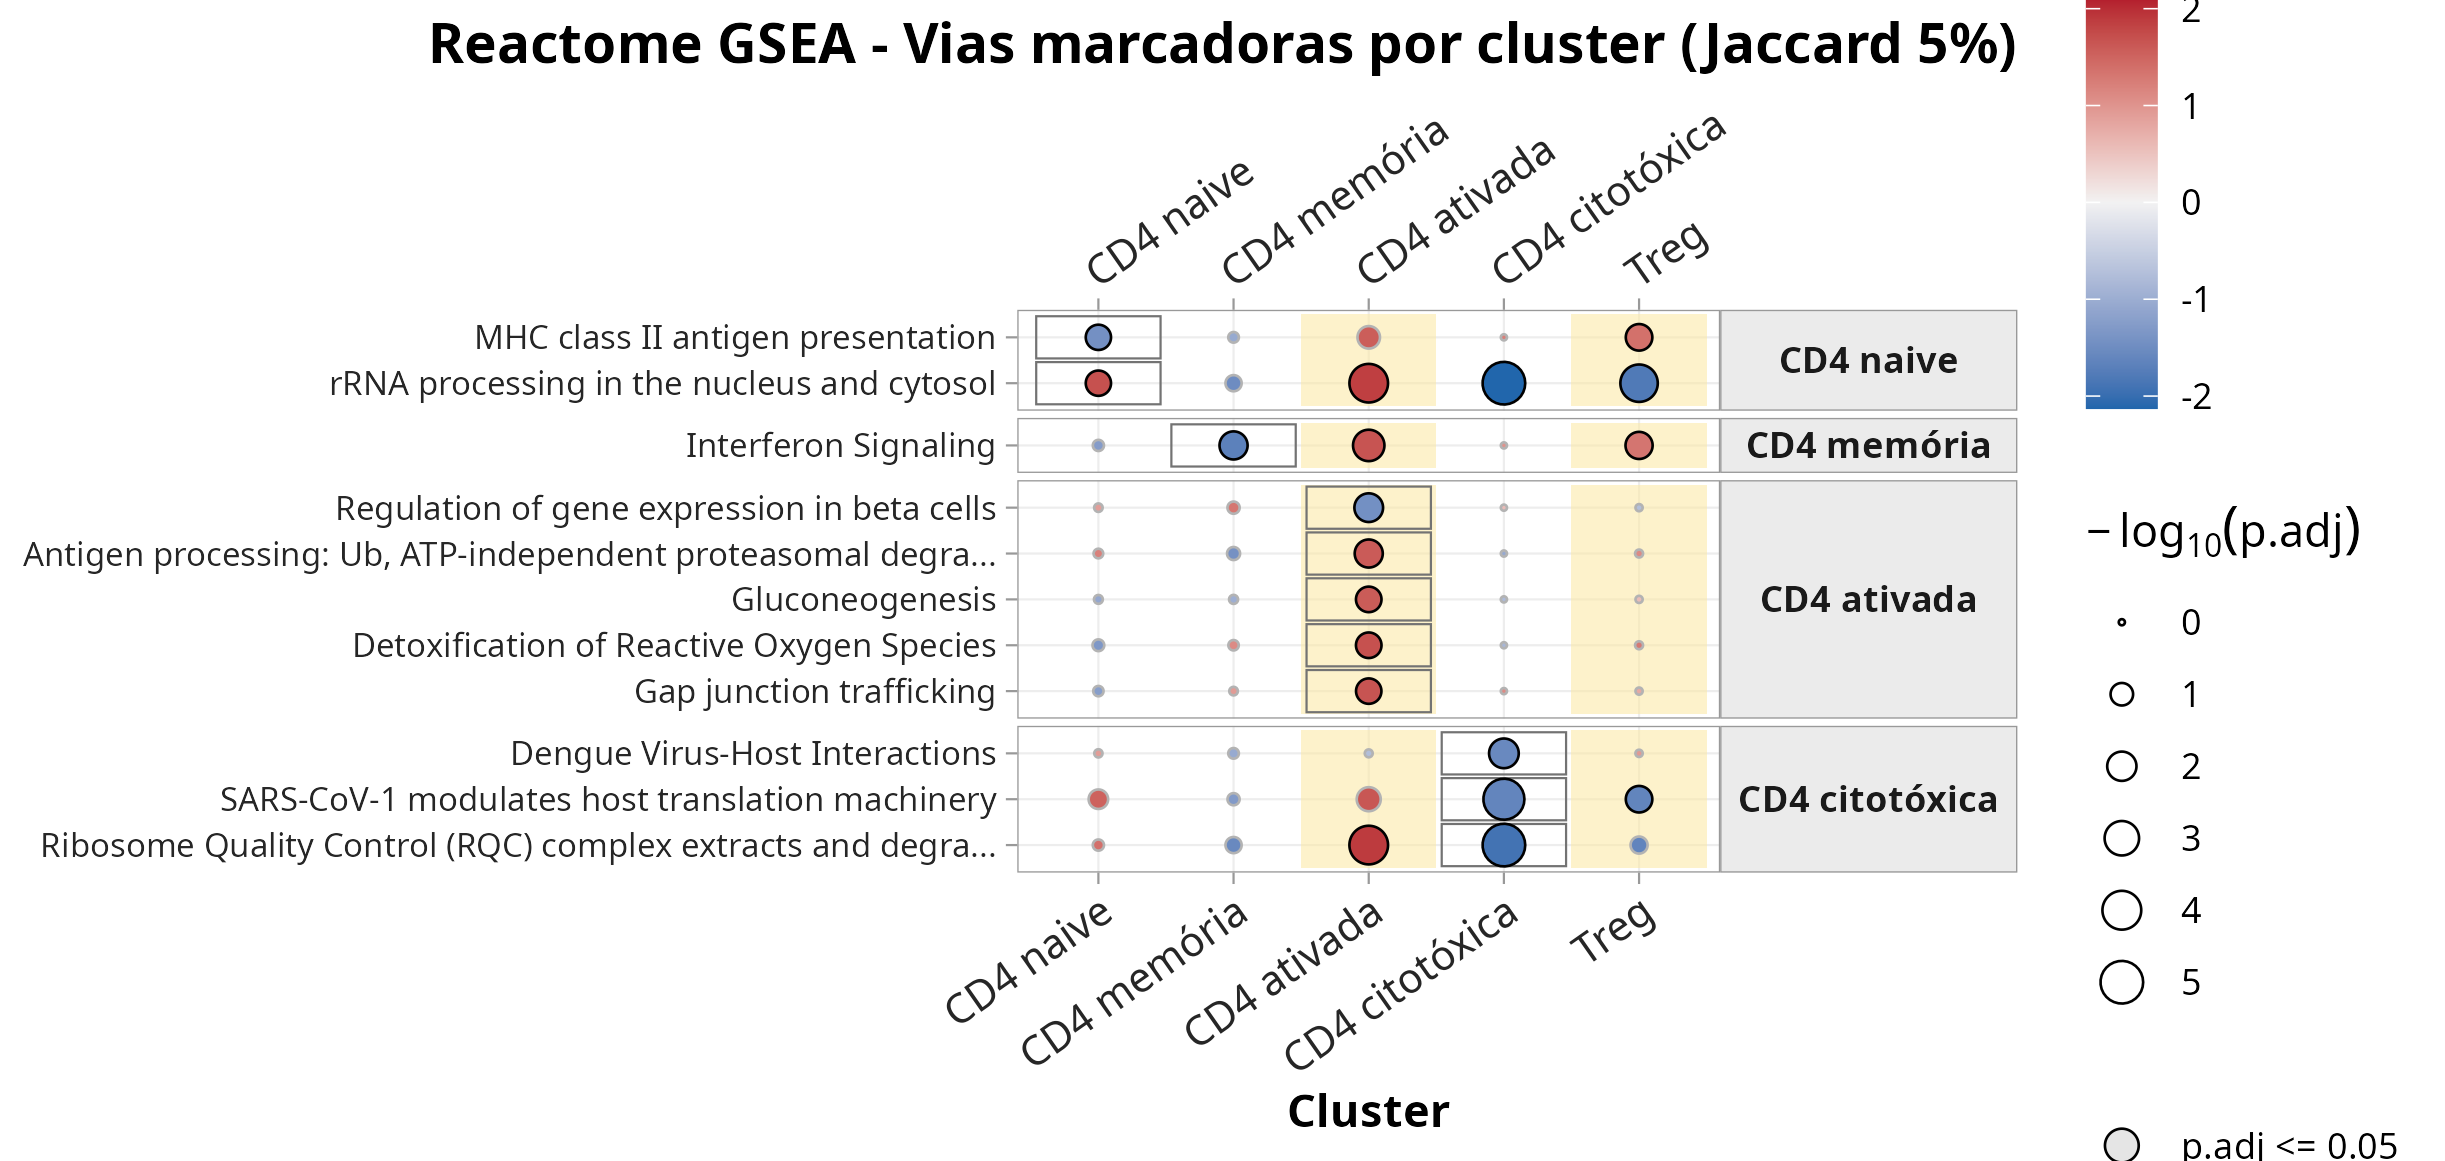

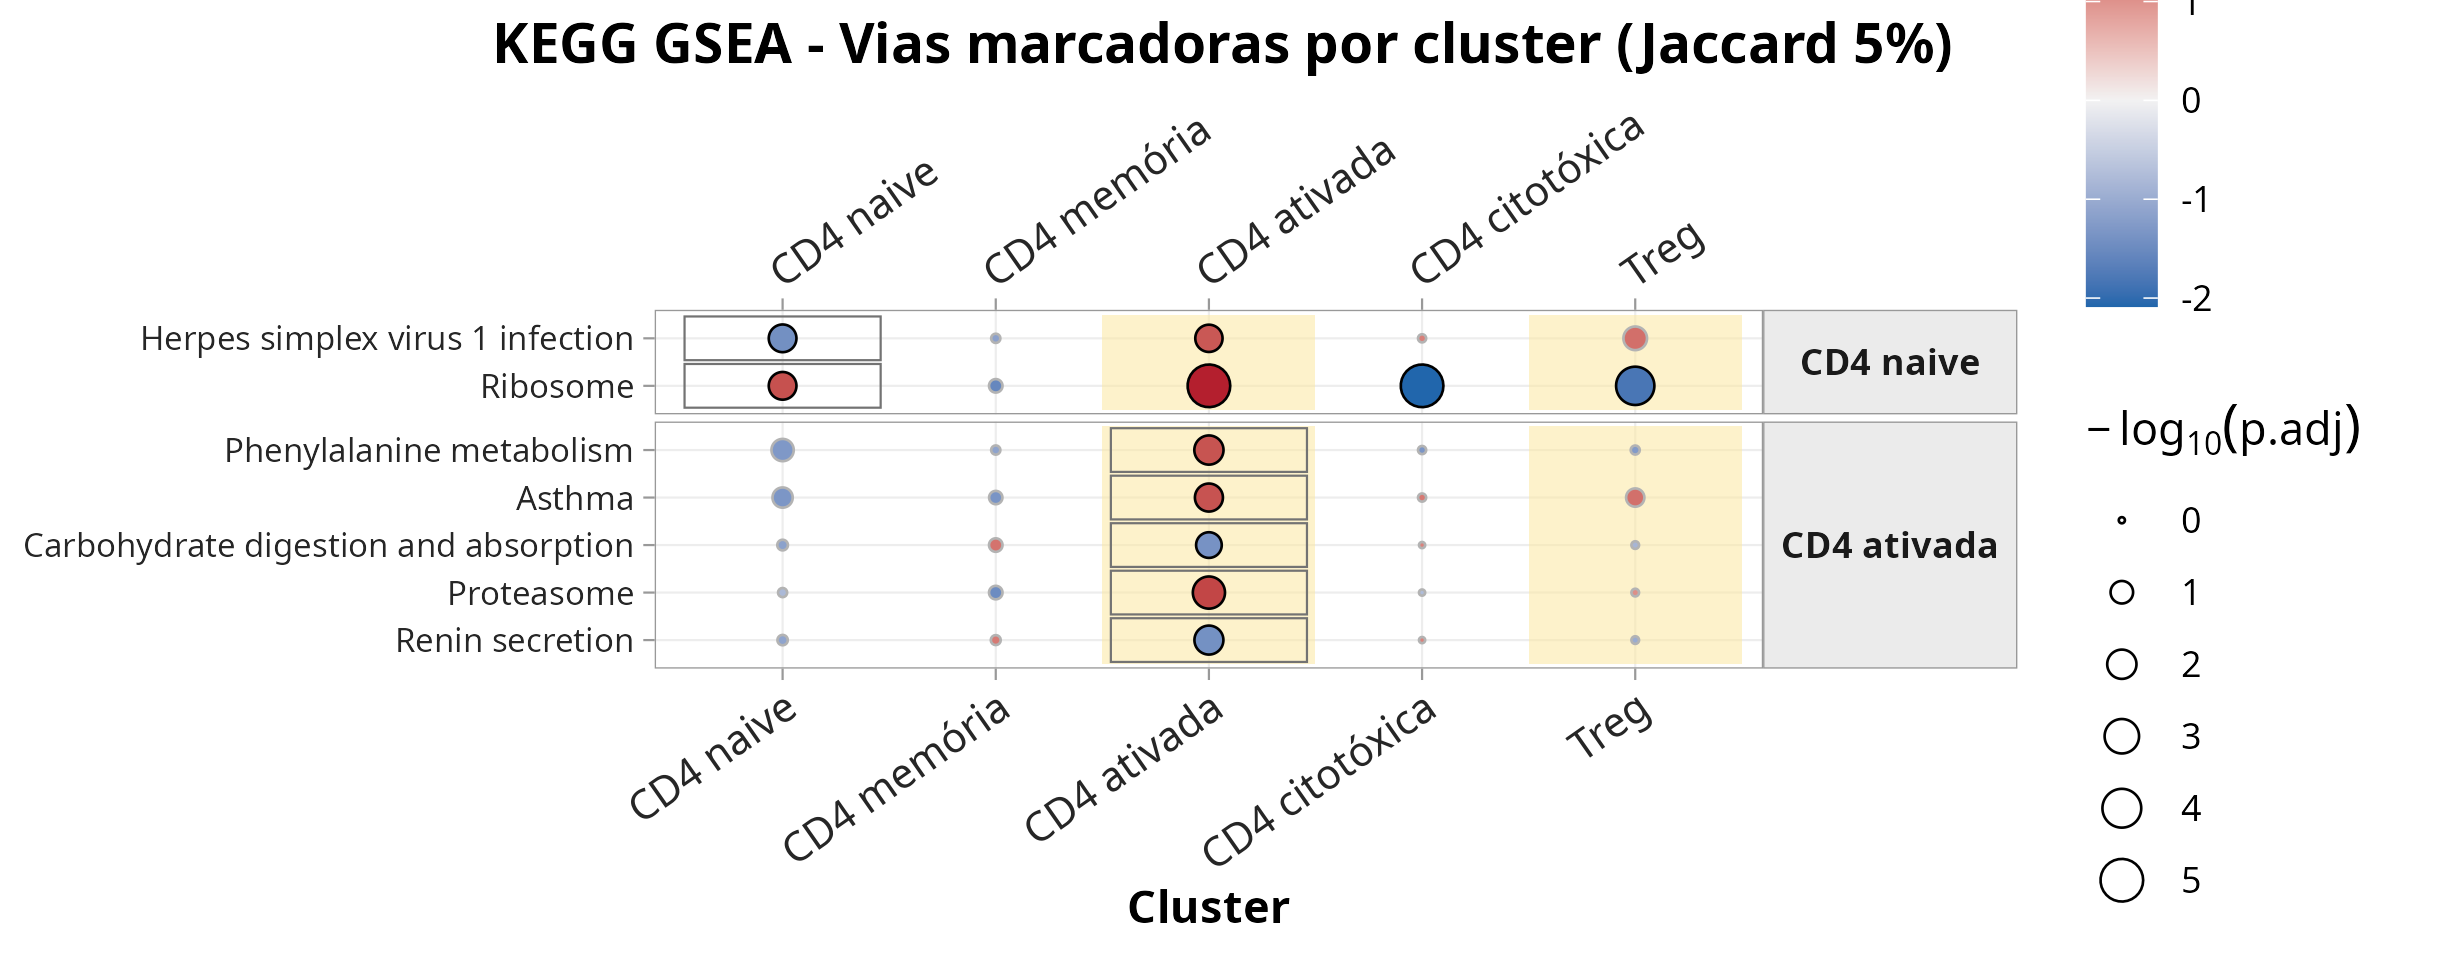

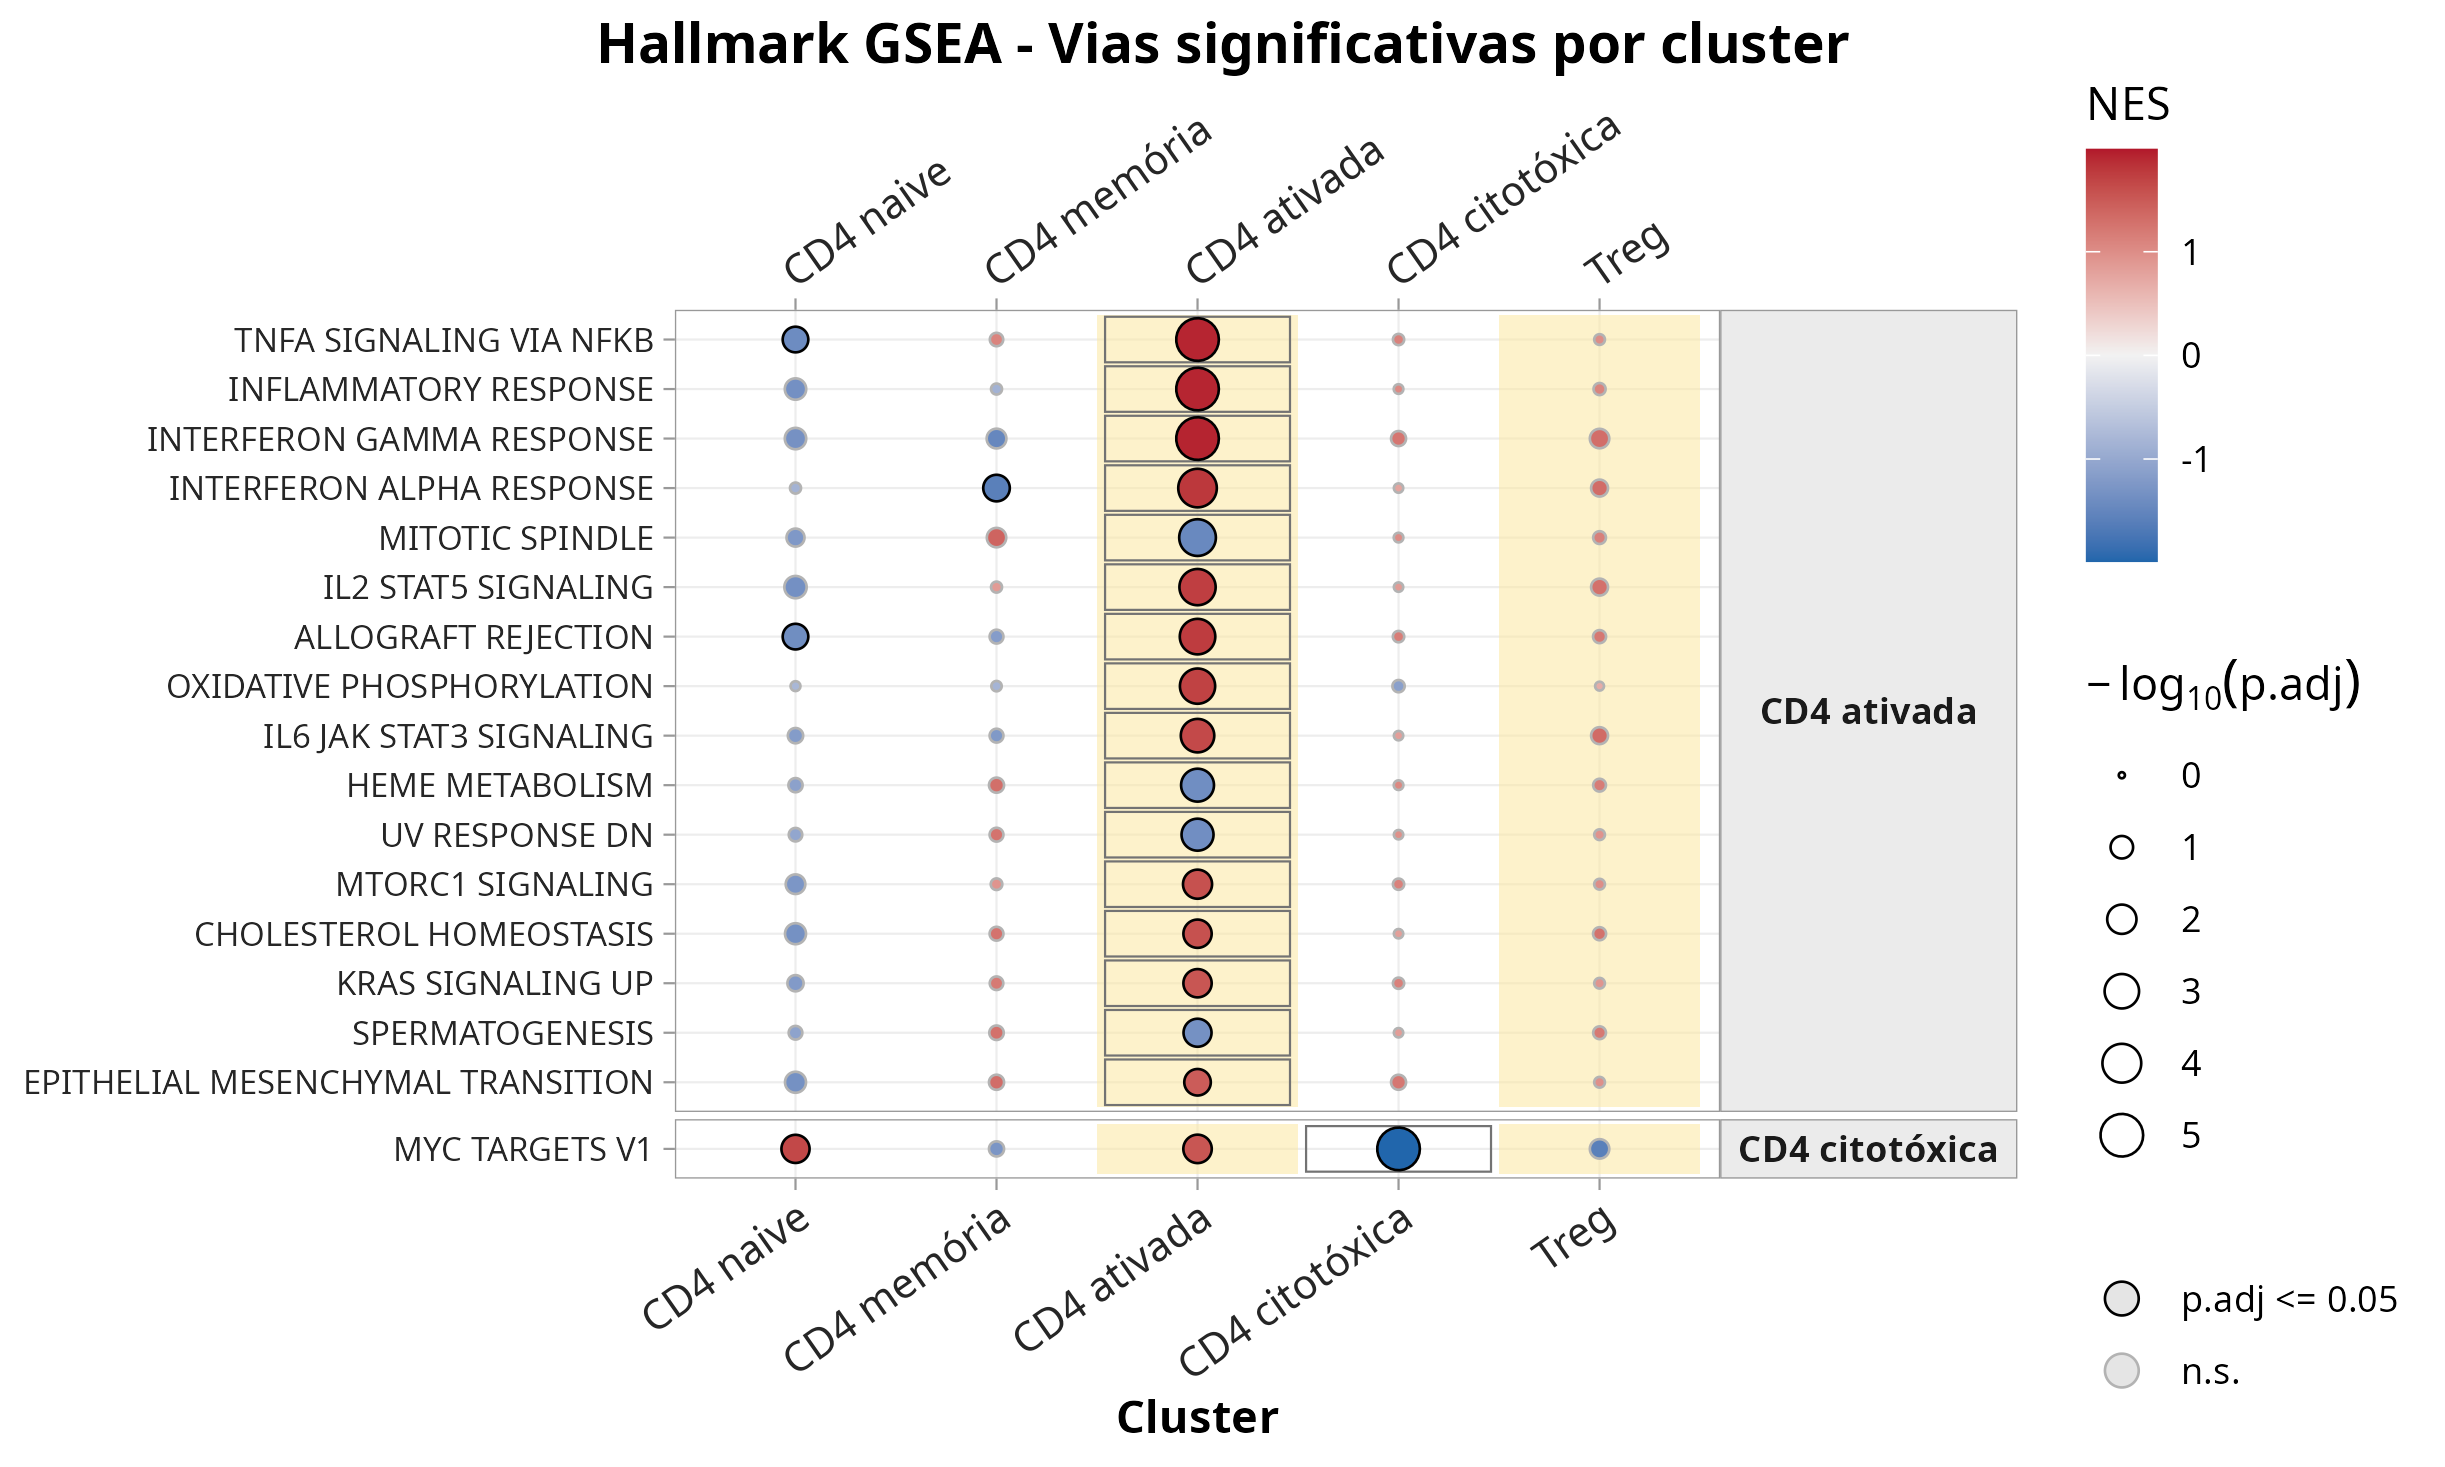

In [5]:
for b in ["reactome", "kegg", "hallmark"]:
    display(Image(filename=str(FIG / "grupo" / f"gsea_{b}_marcadoras_combinado.png"), width=1100))

## 5. Treg × T efetora

O contraste principal (Teff ampla). Na coluna "Treg", NES > 0 = via mais alta na Treg do que na
Teff; a coluna "Teff" é o mesmo teste com o sinal trocado.

In [6]:
def contraste(nome):
    """Vias significativas no contraste Treg × Teff (lado da Treg), por base."""
    linhas = []
    for b, arq in BASES:
        d = pd.read_csv(TAB / nome / arq)
        t = d[(d["cluster"] == "Treg")][["ID", "Description", "setSize", "NES", "p.adjust"]].assign(base=b)
        linhas.append(t)
    return pd.concat(linhas, ignore_index=True)


ce = contraste("treg_teff_ampla")
lado = ce.rename(columns={"NES": "NES ampla", "p.adjust": "p.adjust ampla"})
for run, suf in [("treg_teff_estrita", "estrita"), ("treg_teff_ampla_sinal_log10p", "sinal×log10p"),
                 ("treg_teff_ampla_log2fc", "log2FC")]:
    lado = lado.merge(contraste(run)[["base", "ID", "NES", "p.adjust"]].rename(
        columns={"NES": f"NES {suf}", "p.adjust": f"p.adjust {suf}"}), on=["base", "ID"], how="outer")
io.save_table(lado, NB, "treg_vs_teff_sensibilidade", index=False,
              description="Lado Treg do contraste Treg × Teff: Teff ampla (score do espacial), estrita e dois scores alternativos")
n_sig = pd.DataFrame({c.replace("p.adjust ", ""): lado.groupby("base")[c].apply(lambda s: int((s <= 0.05).sum()))
                      for c in lado.columns if c.startswith("p.adjust")})
print("vias com p.adj ≤ 0,05 no lado Treg, por ranking:"); display(n_sig)
sig_e = lado[(lado[[c for c in lado.columns if c.startswith("p.adjust")]] <= 0.05).any(axis=1)]
cols_nes = [c for c in lado.columns if c.startswith("NES")]
for b in ["Hallmark", "KEGG", "Reactome"]:
    t = sig_e[sig_e["base"] == b].sort_values("NES sinal×log10p")
    conc = (np.sign(t[cols_nes]).nunique(axis=1) == 1).sum()
    print(f"\n== {b}: {len(t)} vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: {conc}")
    with pd.option_context("display.max_colwidth", 60, "display.width", 250):
        display(pd.concat([t.head(12), t.tail(12)]).drop_duplicates()[["Description", "setSize"] + [
            c for c in lado.columns if c.startswith(("NES", "p.adjust"))]].round(3))

vias com p.adj ≤ 0,05 no lado Treg, por ranking:


,ampla,estrita,sinal×log10p,log2FC
base,,,,
Hallmark,0,0,6,14
KEGG,1,1,23,21
Reactome,22,30,41,134



== Hallmark: 17 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 7


,Description,setSize,NES ampla,p.adjust ampla,NES estrita,p.adjust estrita,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
9,COAGULATION,110,-1.439,0.490,-1.673,0.065,-1.563,0.068,-1.454,0.044
31,MYC TARGETS V1,200,-1.383,0.490,-1.210,0.593,-1.561,0.022,-0.698,1.000
48,WNT BETA CATENIN SIGNALING,38,-1.301,0.797,1.267,0.593,-1.220,0.513,-1.854,0.005
33,MYOGENESIS,165,-1.223,0.797,-1.188,0.613,-0.989,0.698,-1.679,0.001
13,EPITHELIAL MESENCHYMAL TRANSITION,166,-0.880,0.924,-1.075,0.687,0.777,0.890,-1.706,0.000
28,KRAS SIGNALING UP,177,0.704,0.924,0.744,0.952,0.927,0.802,-1.917,0.000
18,GLYCOLYSIS,187,0.822,0.924,0.688,0.959,0.989,0.752,-1.476,0.007
44,TNFA SIGNALING VIA NFKB,196,0.728,0.924,-1.394,0.436,1.011,0.720,-1.799,0.000
24,INFLAMMATORY RESPONSE,187,0.941,0.924,-1.190,0.613,1.189,0.471,-1.557,0.002
10,COMPLEMENT,187,0.910,0.924,-1.169,0.613,1.225,0.437,-1.436,0.013



== KEGG: 35 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 18


,Description,setSize,NES ampla,p.adjust ampla,NES estrita,p.adjust estrita,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
139,Ribosome,171,-1.792,0.008,-1.870,0.000,-2.281,0.000,-1.842,0.000
358,Coronavirus disease,197,-1.037,0.979,-1.263,0.853,-1.871,0.000,-1.356,0.113
208,Wnt signaling pathway,153,-1.499,0.668,0.707,0.962,-1.270,0.467,-1.608,0.008
378,Acute myeloid leukemia,64,-1.191,0.977,0.958,0.925,-1.042,0.892,-1.848,0.008
242,IL-17 signaling pathway,77,-0.761,0.985,-1.183,0.853,0.866,0.972,-2.277,0.000
340,Chagas disease,96,-1.010,0.979,-1.325,0.853,0.881,0.972,-1.891,0.002
234,Toll-like receptor signaling pathway,91,0.696,0.985,-1.412,0.853,1.127,0.856,-1.683,0.018
170,Chemokine signaling pathway,169,0.926,0.983,-1.291,0.853,1.140,0.820,-1.913,0.000
168,Cytokine-cytokine receptor interaction,219,1.114,0.977,-1.164,0.853,1.302,0.363,-1.904,0.000
239,JAK-STAT signaling pathway,132,1.136,0.977,1.186,0.853,1.314,0.445,-1.567,0.039



== Reactome: 138 vias com p.adj ≤ 0,05 em algum ranking; mesmo sinal nos quatro: 115


,Description,setSize,NES ampla,p.adjust ampla,NES estrita,p.adjust estrita,NES sinal×log10p,p.adjust sinal×log10p,NES log2FC,p.adjust log2FC
1444,rRNA processing,207,-1.736,0.002,-1.734,0.006,-2.291,0.000,-1.552,0.015
1342,Major pathway of rRNA processing in the nucleolus and cy...,180,-1.726,0.003,-1.746,0.006,-2.269,0.000,-1.665,0.004
1543,rRNA processing in the nucleus and cytosol,190,-1.729,0.004,-1.738,0.006,-2.267,0.000,-1.664,0.004
1816,Cellular response to starvation,153,-1.729,0.005,-1.779,0.003,-2.250,0.000,-1.837,0.000
612,Influenza Viral RNA Transcription and Replication,134,-1.711,0.020,-1.703,0.018,-2.234,0.000,-1.828,0.001
1454,Translation,364,-1.796,0.000,-1.725,0.003,-2.232,0.000,-1.167,0.326
2004,Ribosome-associated quality control,143,-1.704,0.040,-1.772,0.006,-2.216,0.000,-1.845,0.001
1452,Cap-dependent Translation Initiation,118,-1.703,0.020,-1.759,0.010,-2.208,0.000,-2.170,0.000
1445,Eukaryotic Translation Initiation,118,-1.703,0.020,-1.759,0.010,-2.208,0.000,-2.170,0.000
1618,Regulation of expression of SLITs and ROBOs,152,-1.716,0.013,-1.766,0.006,-2.208,0.000,-1.829,0.000


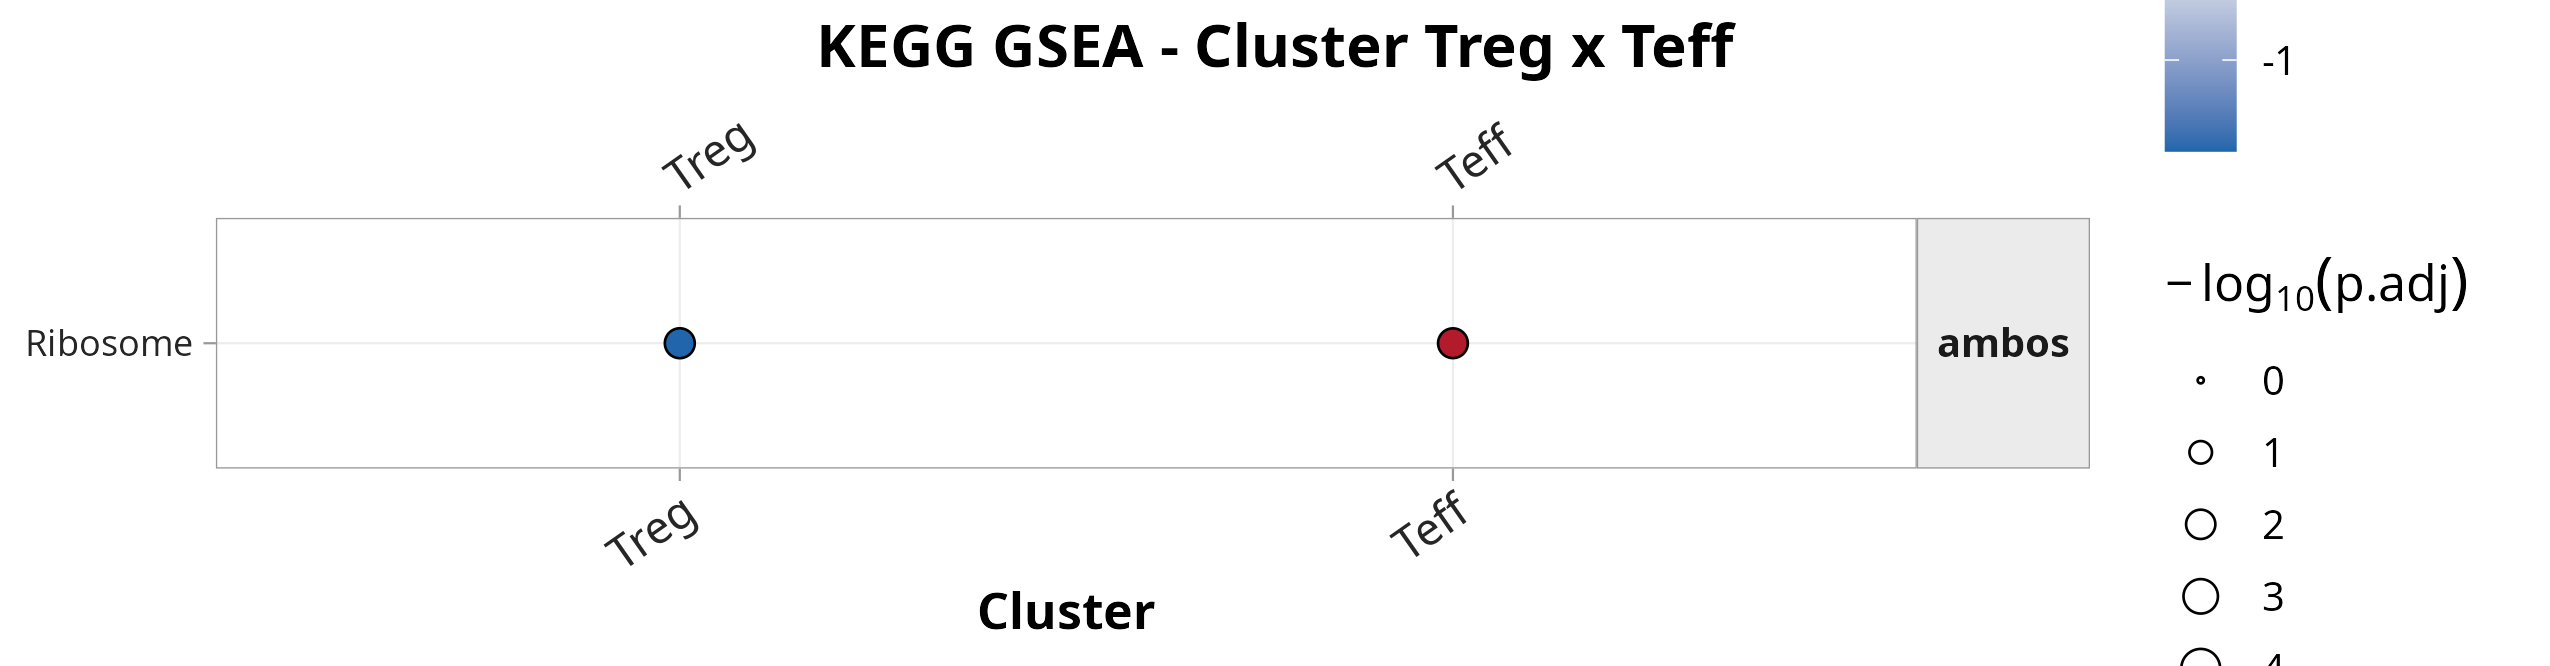

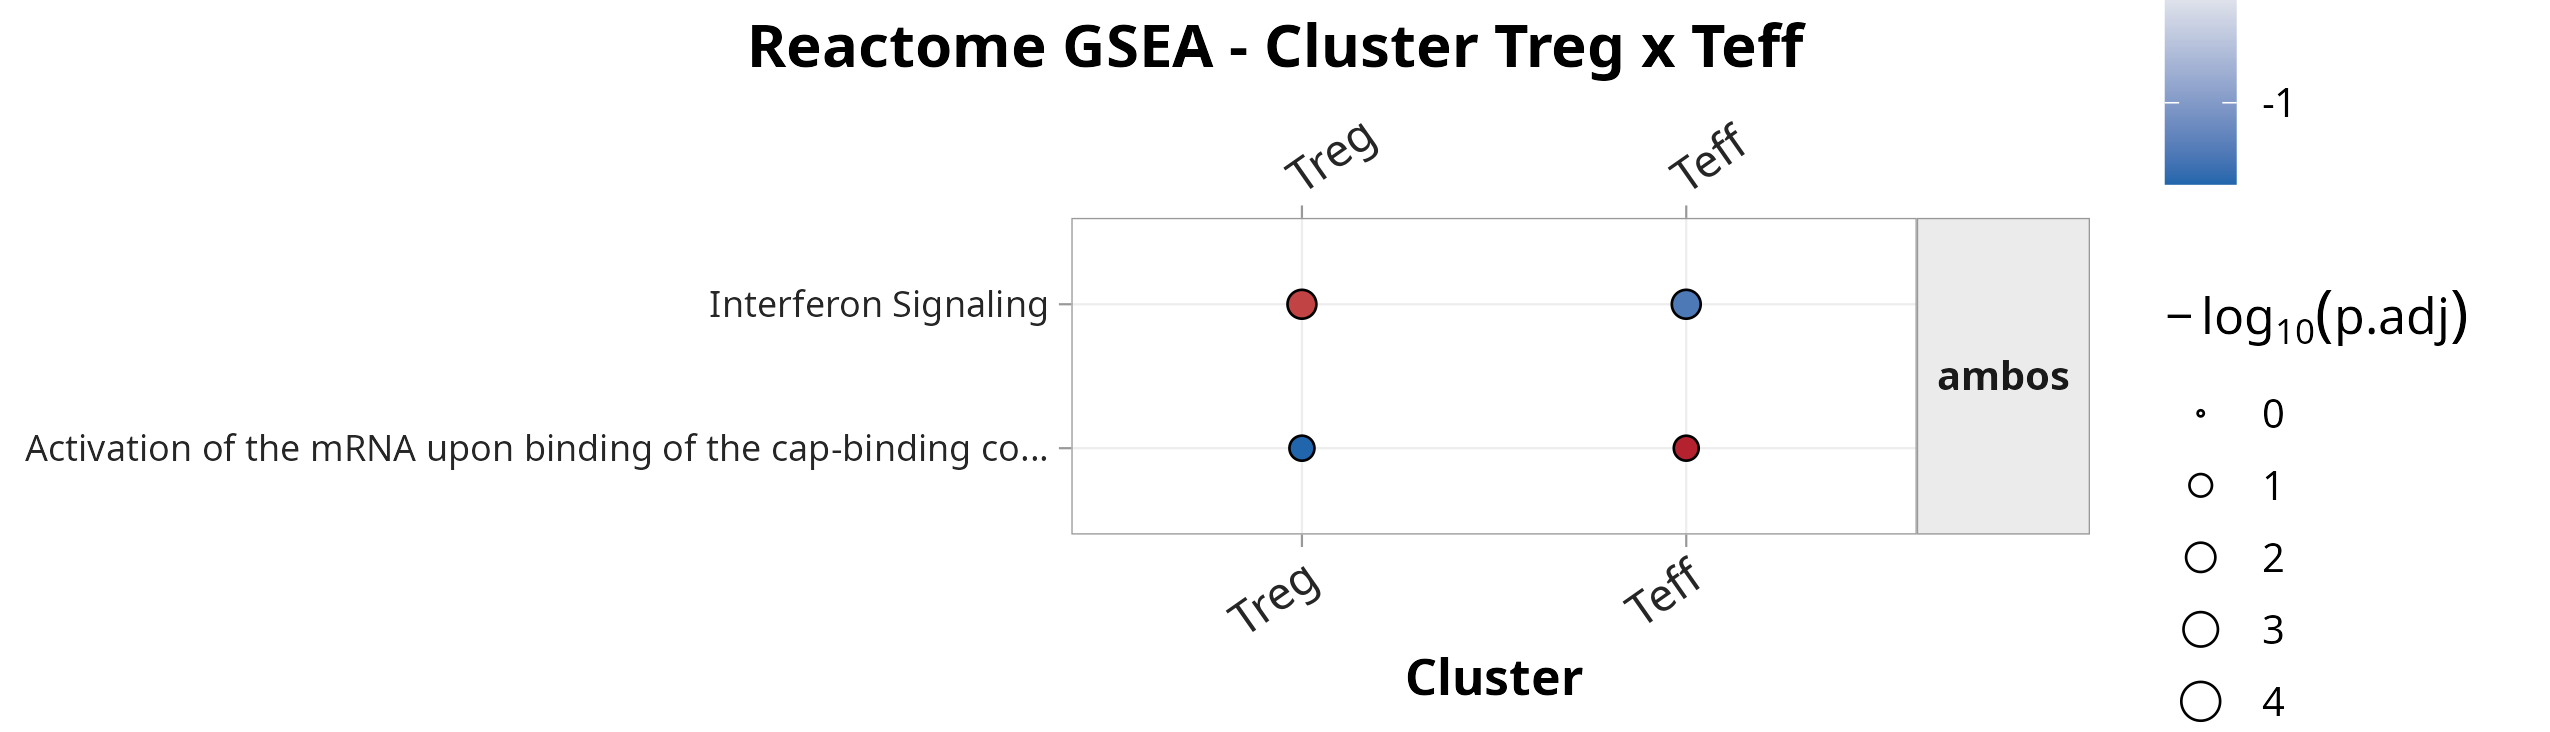

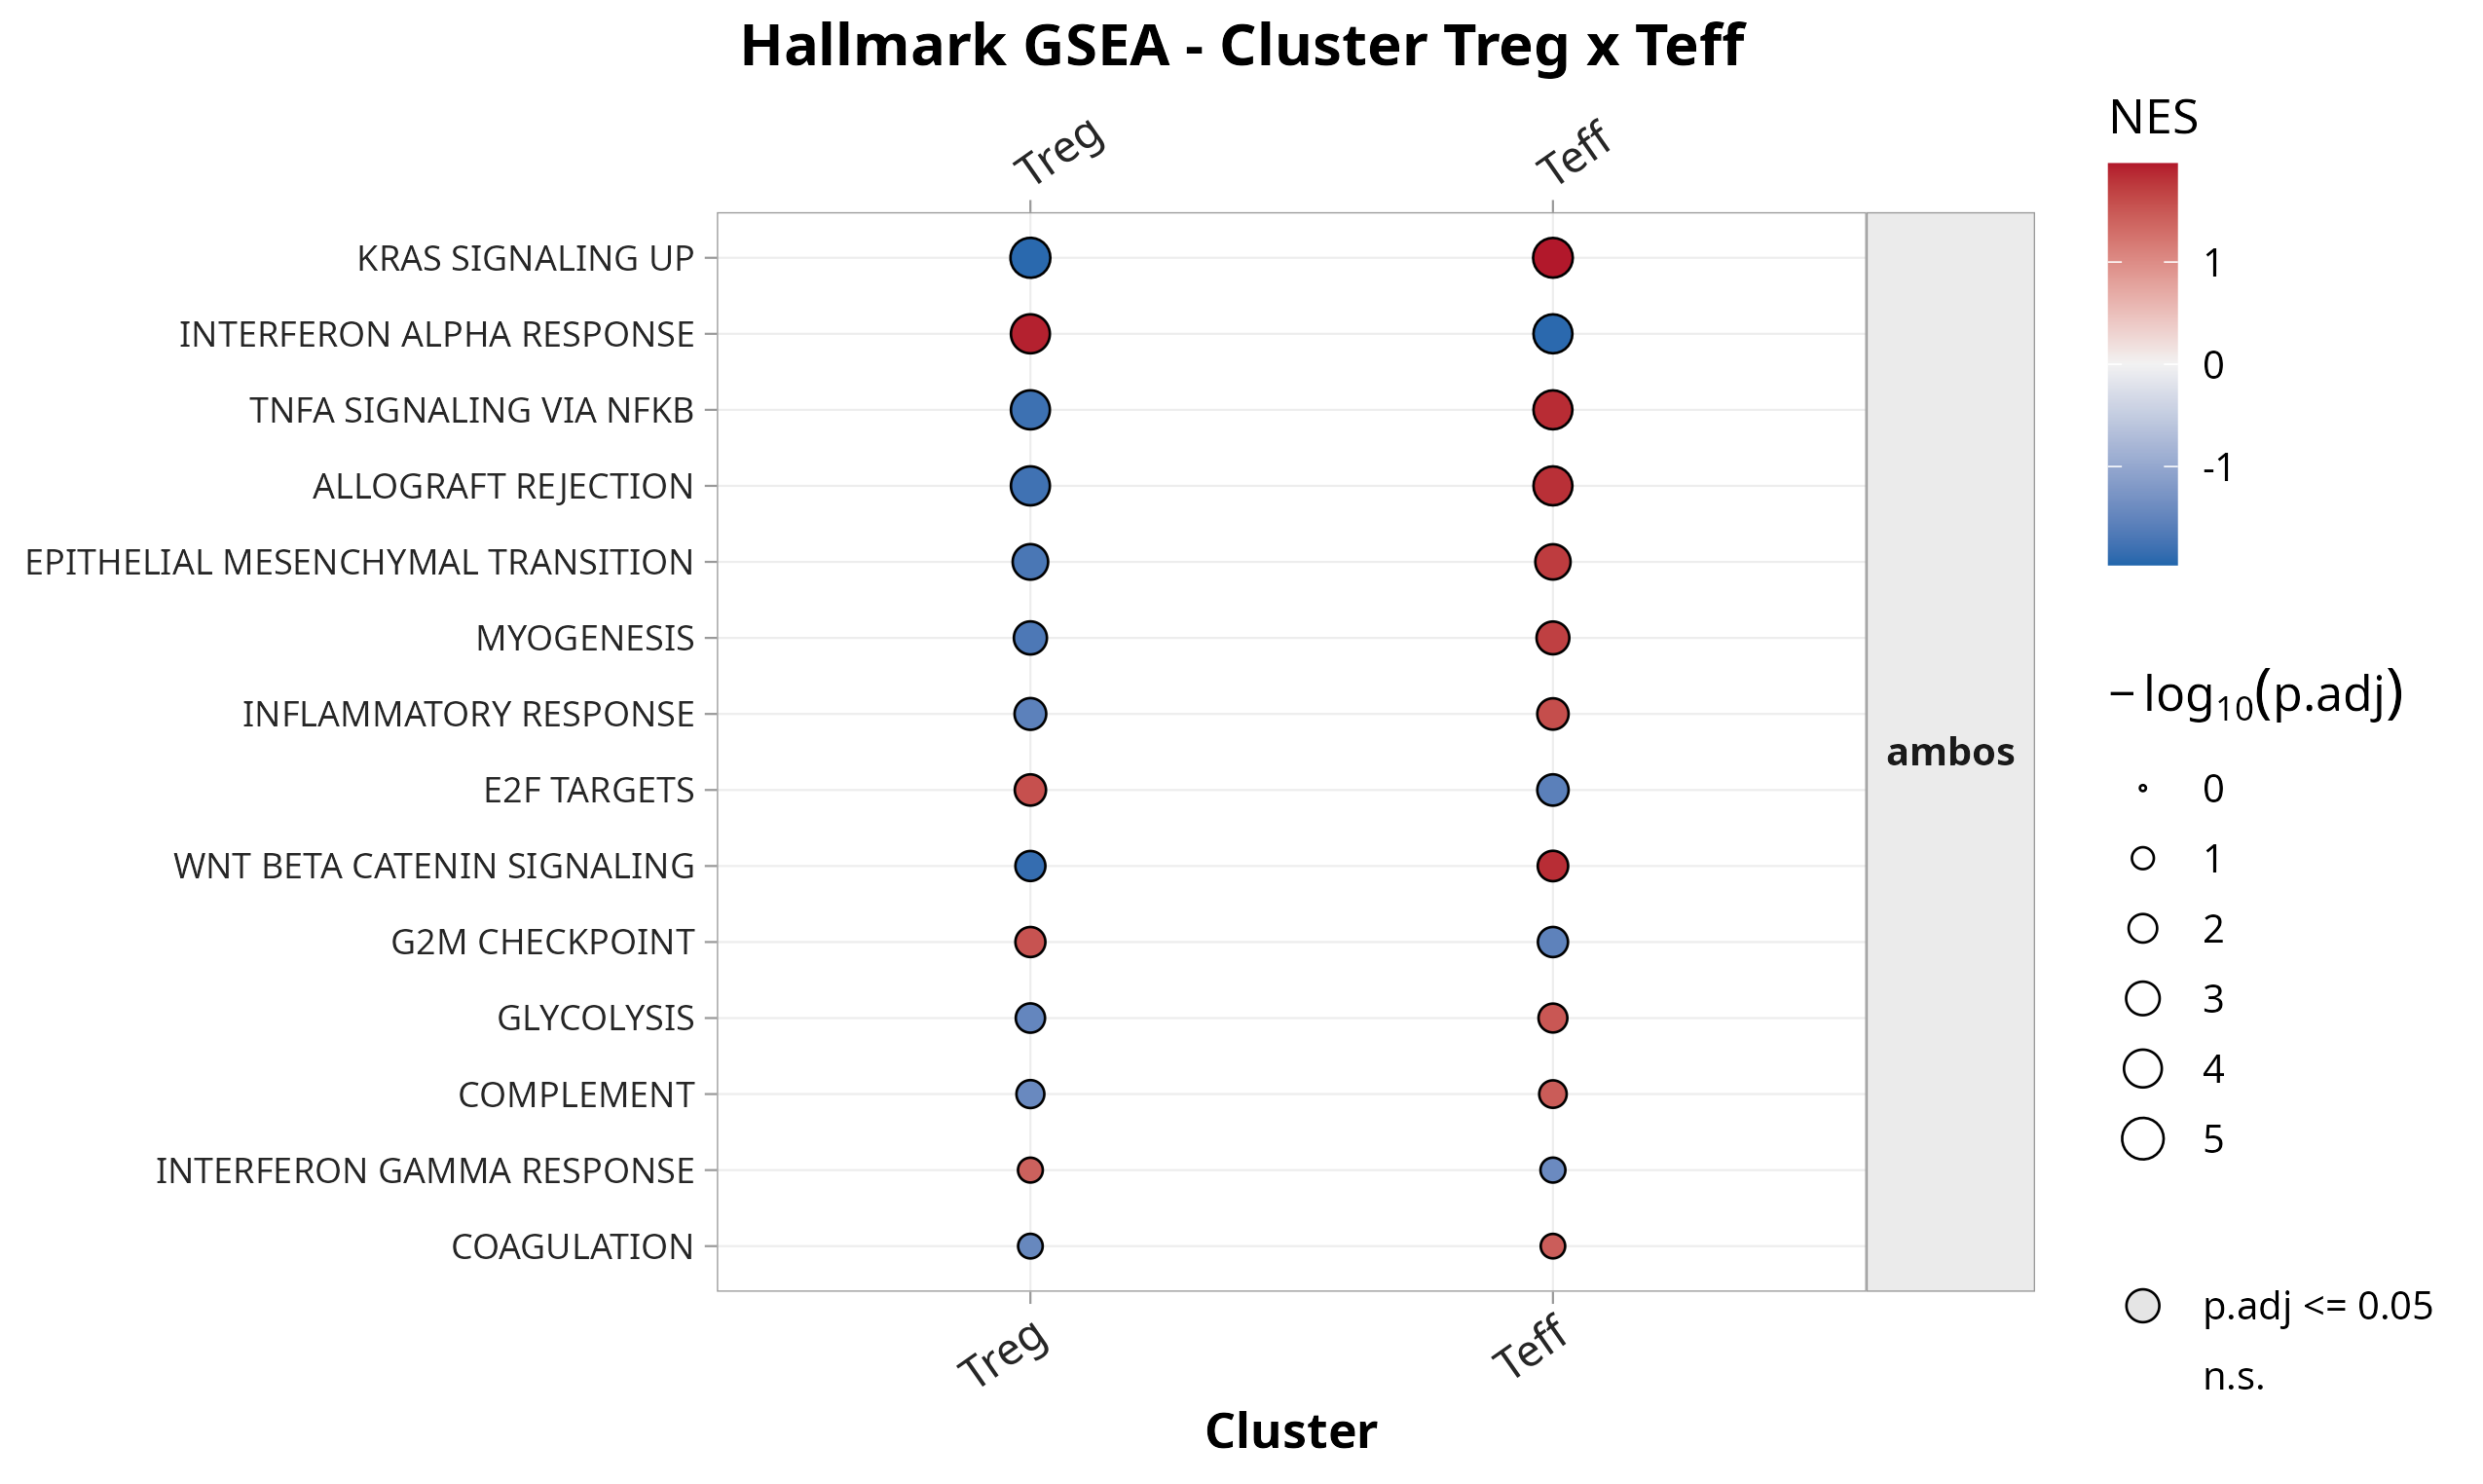

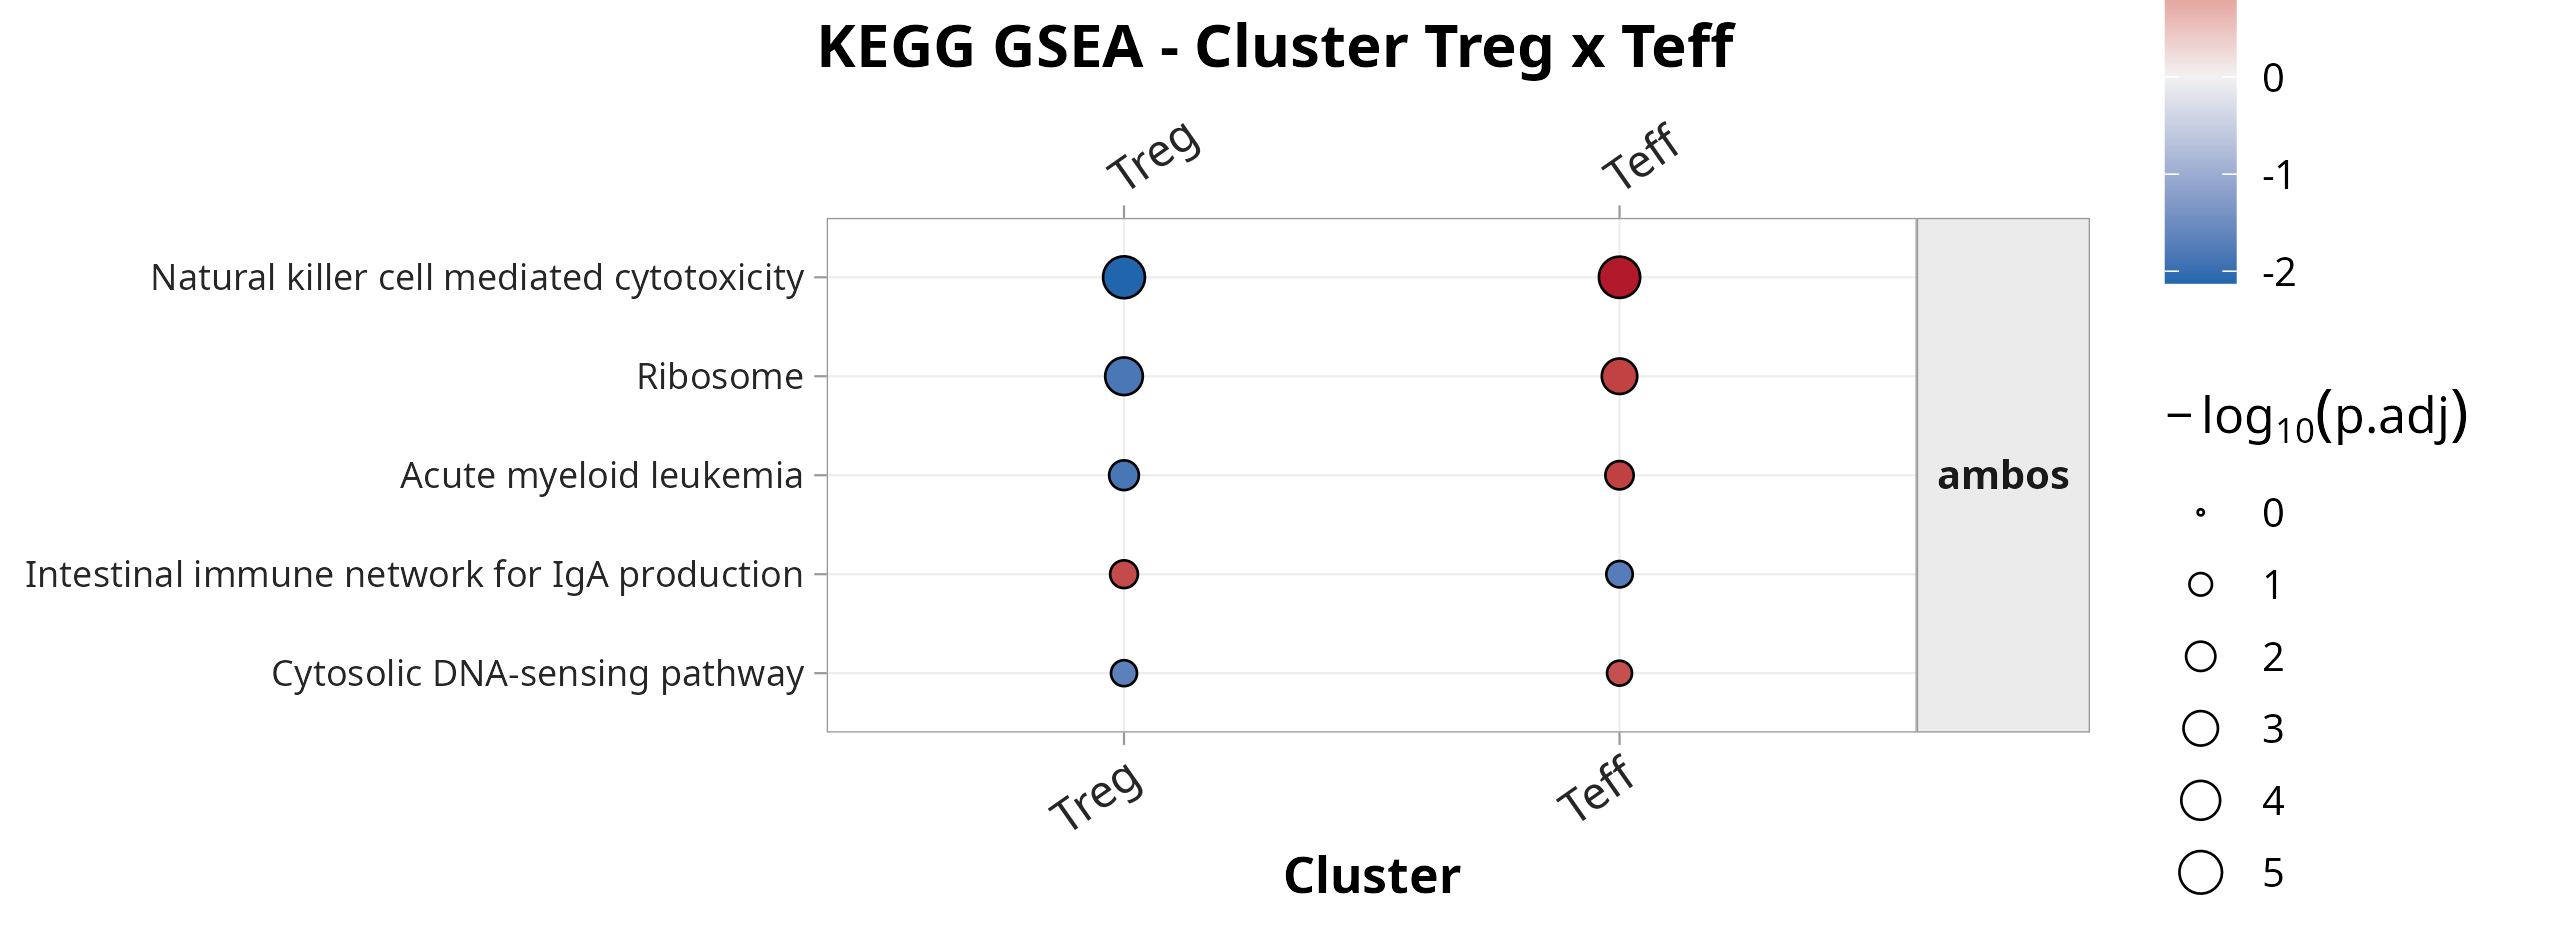

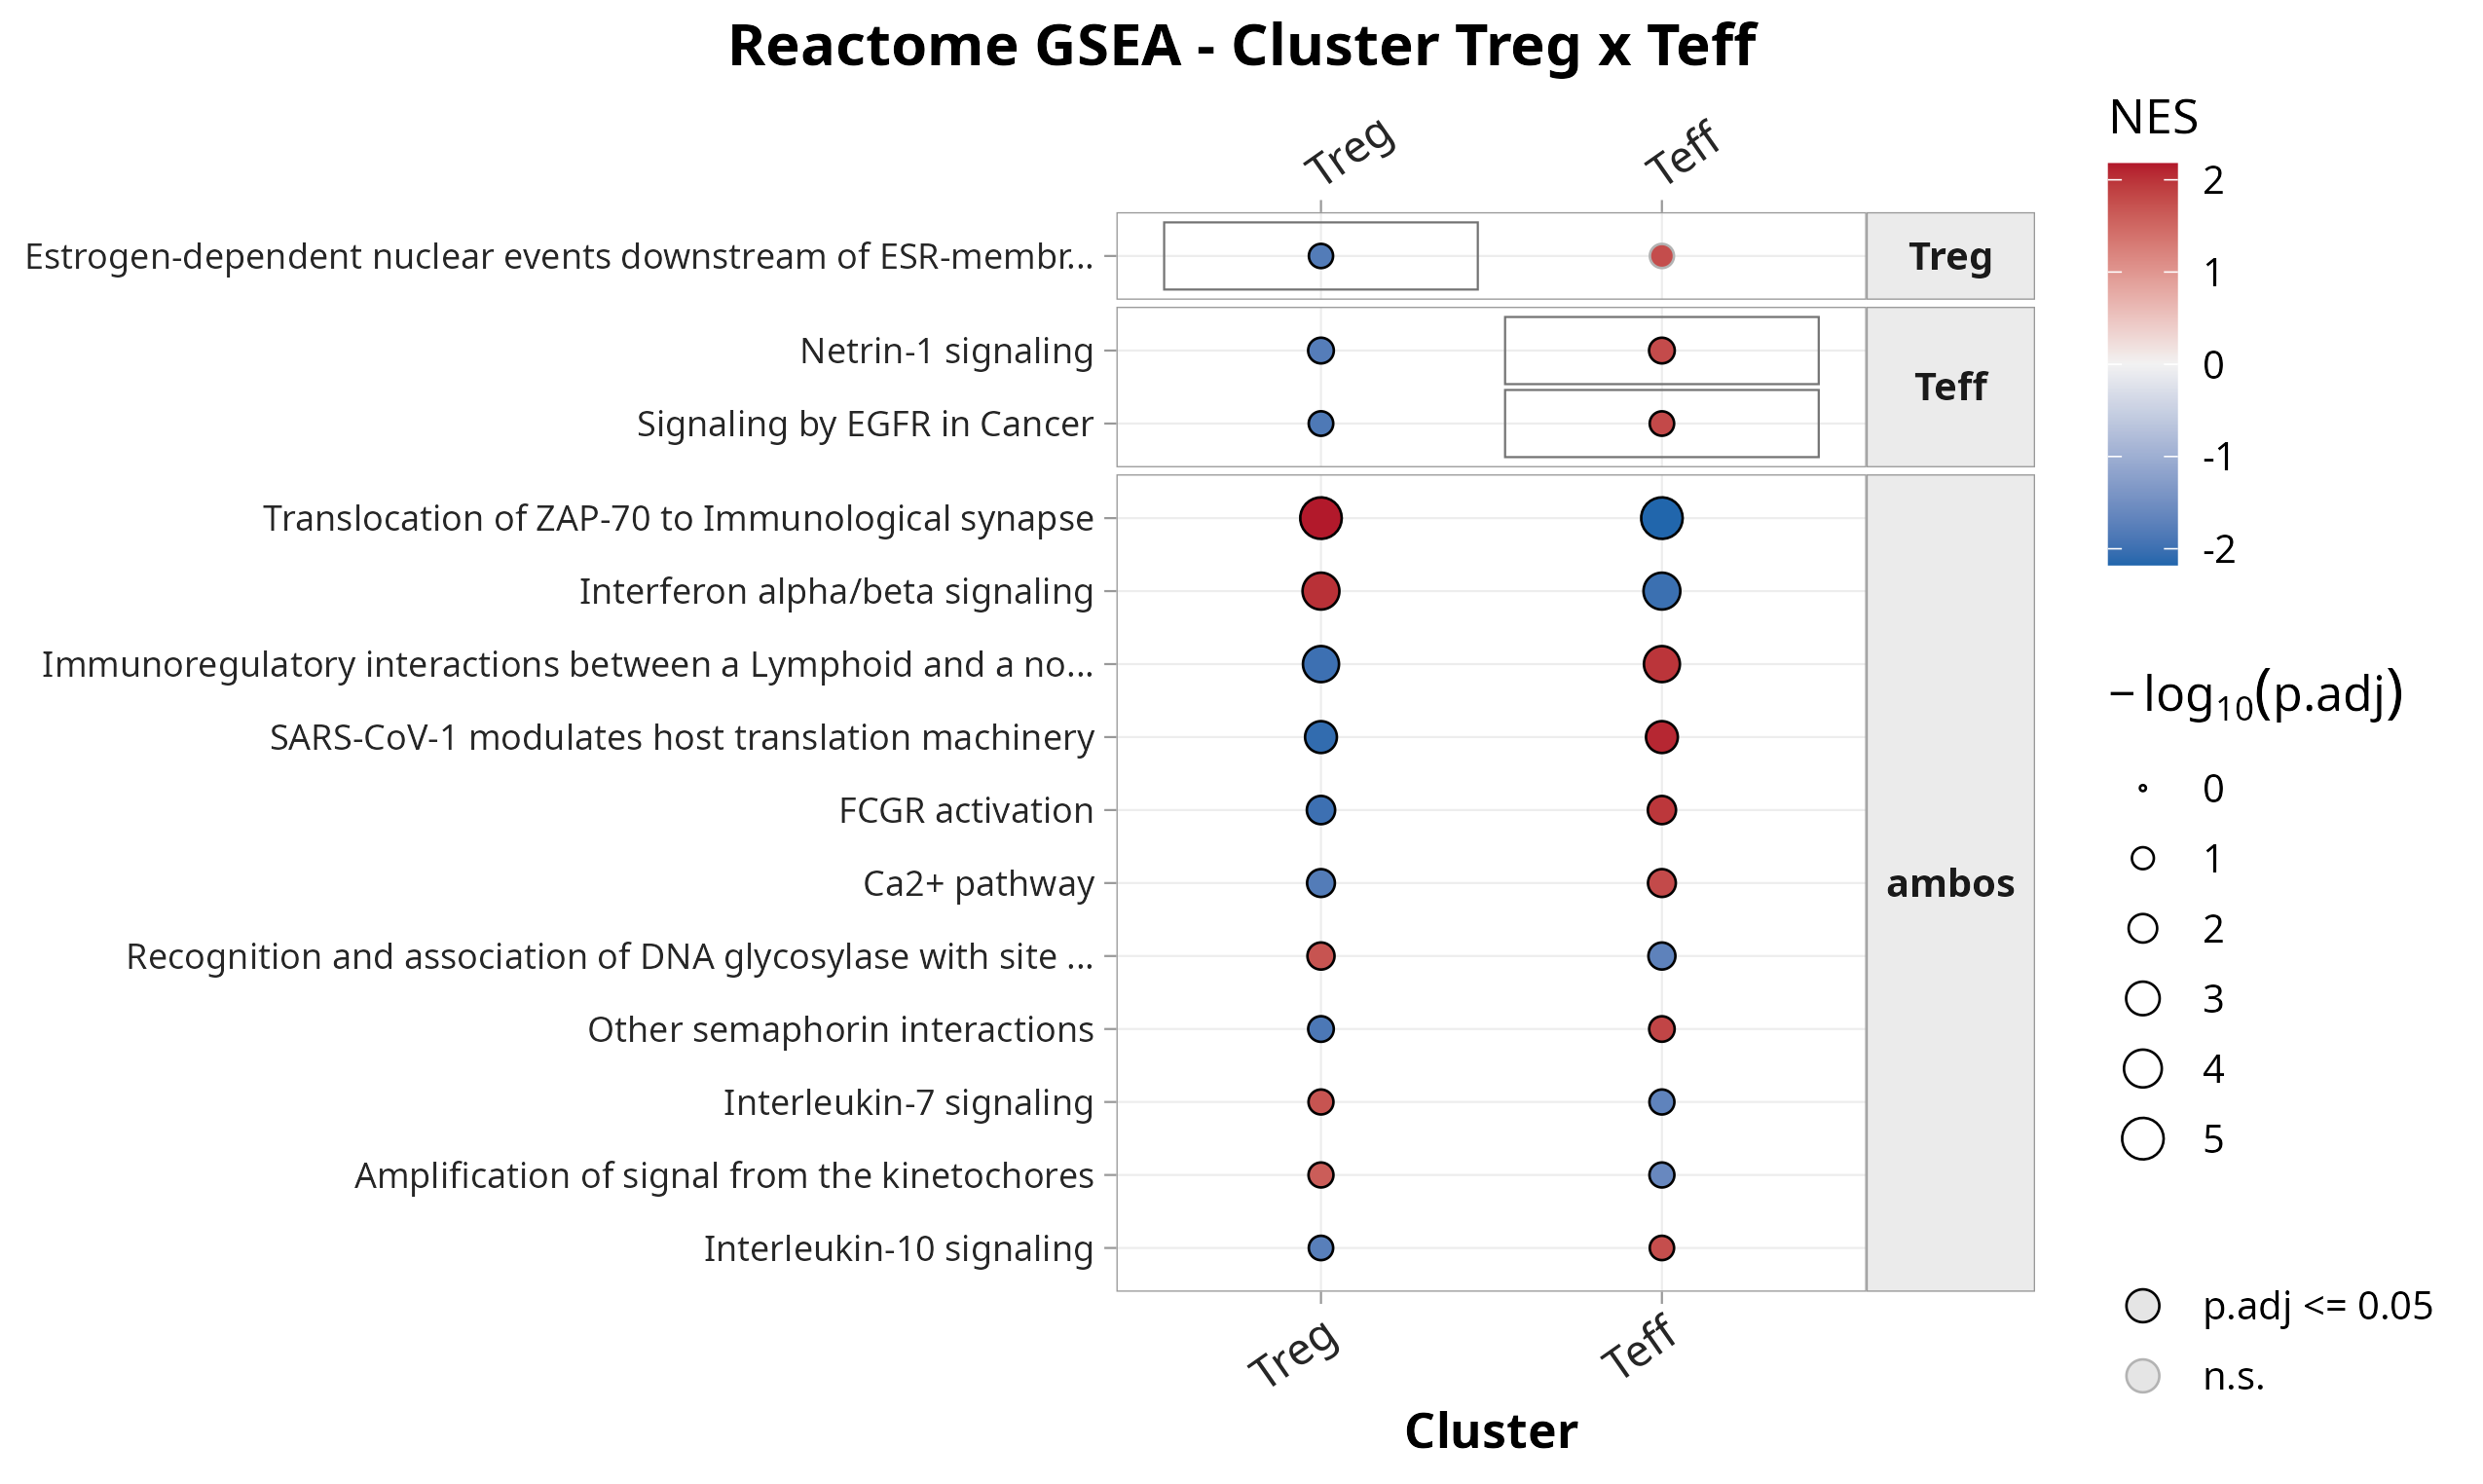

In [7]:
for run, b in [(r, b) for r in ["treg_teff_ampla", "treg_teff_ampla_log2fc"] for b in ["hallmark", "kegg", "reactome"]]:
    p = FIG / run / f"gsea_{b}_comparacao_Treg_vs_Teff.png"
    if p.exists():
        display(Image(filename=str(p), width=850))

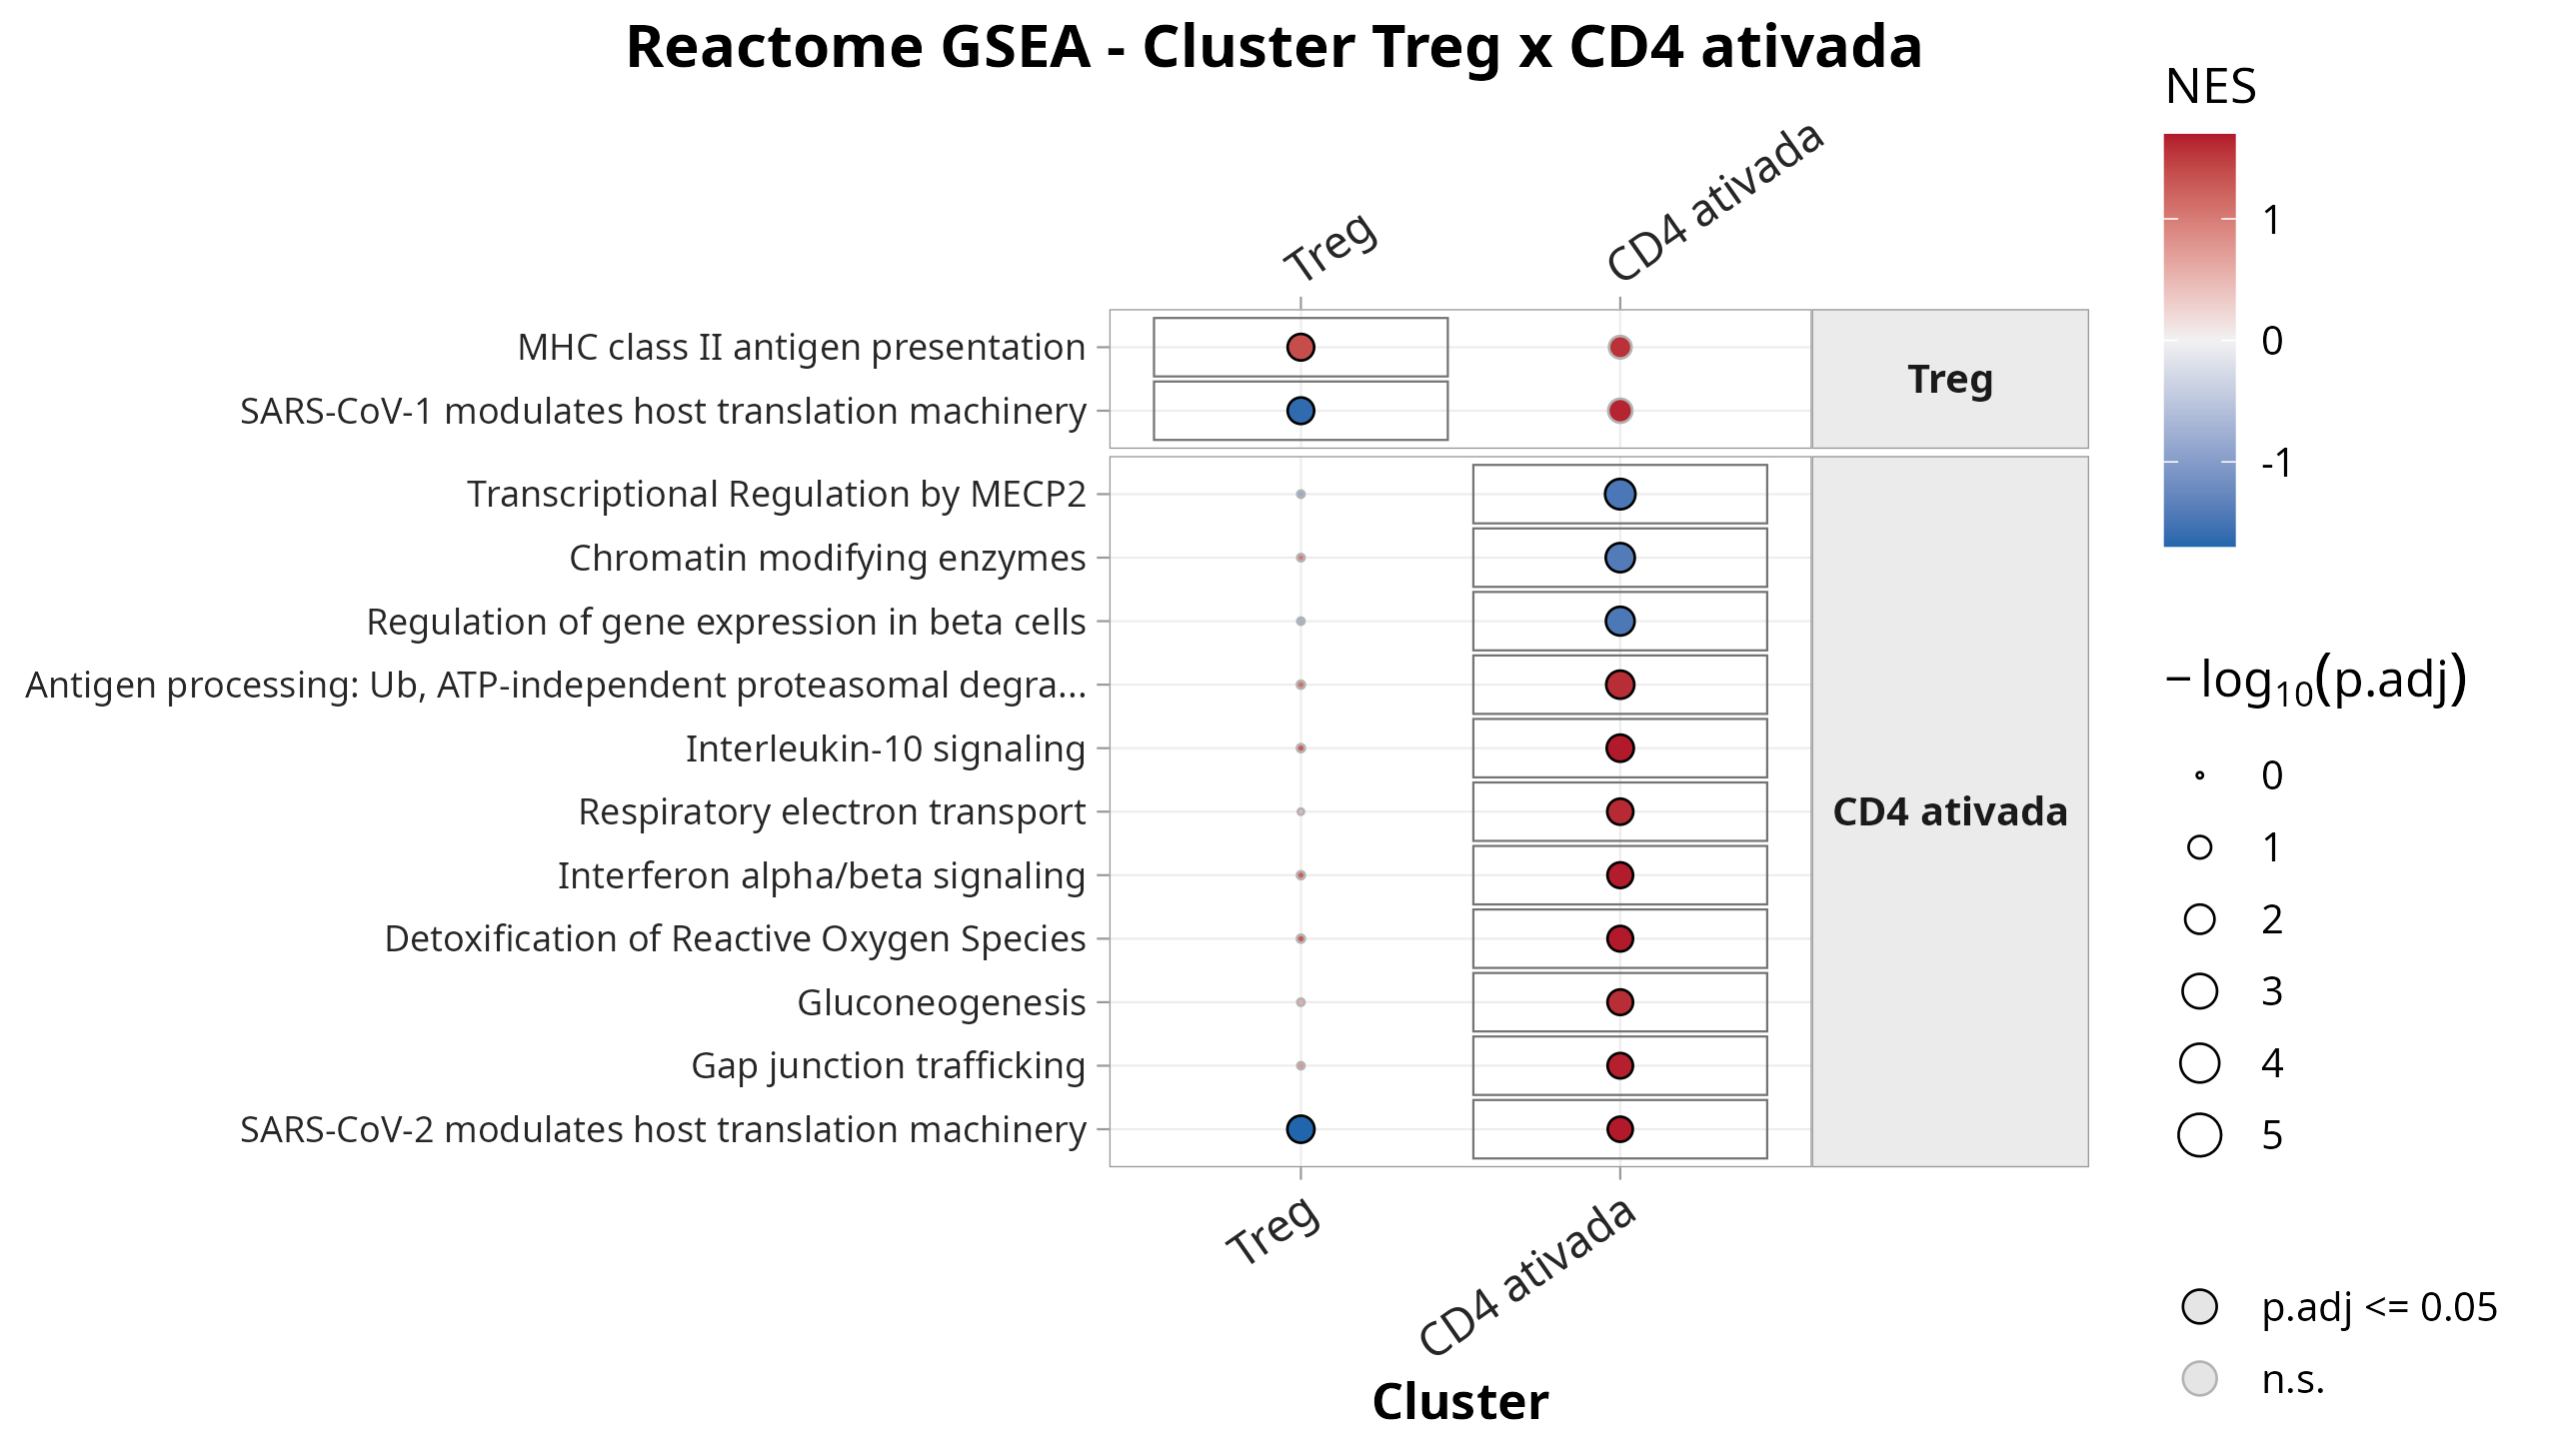

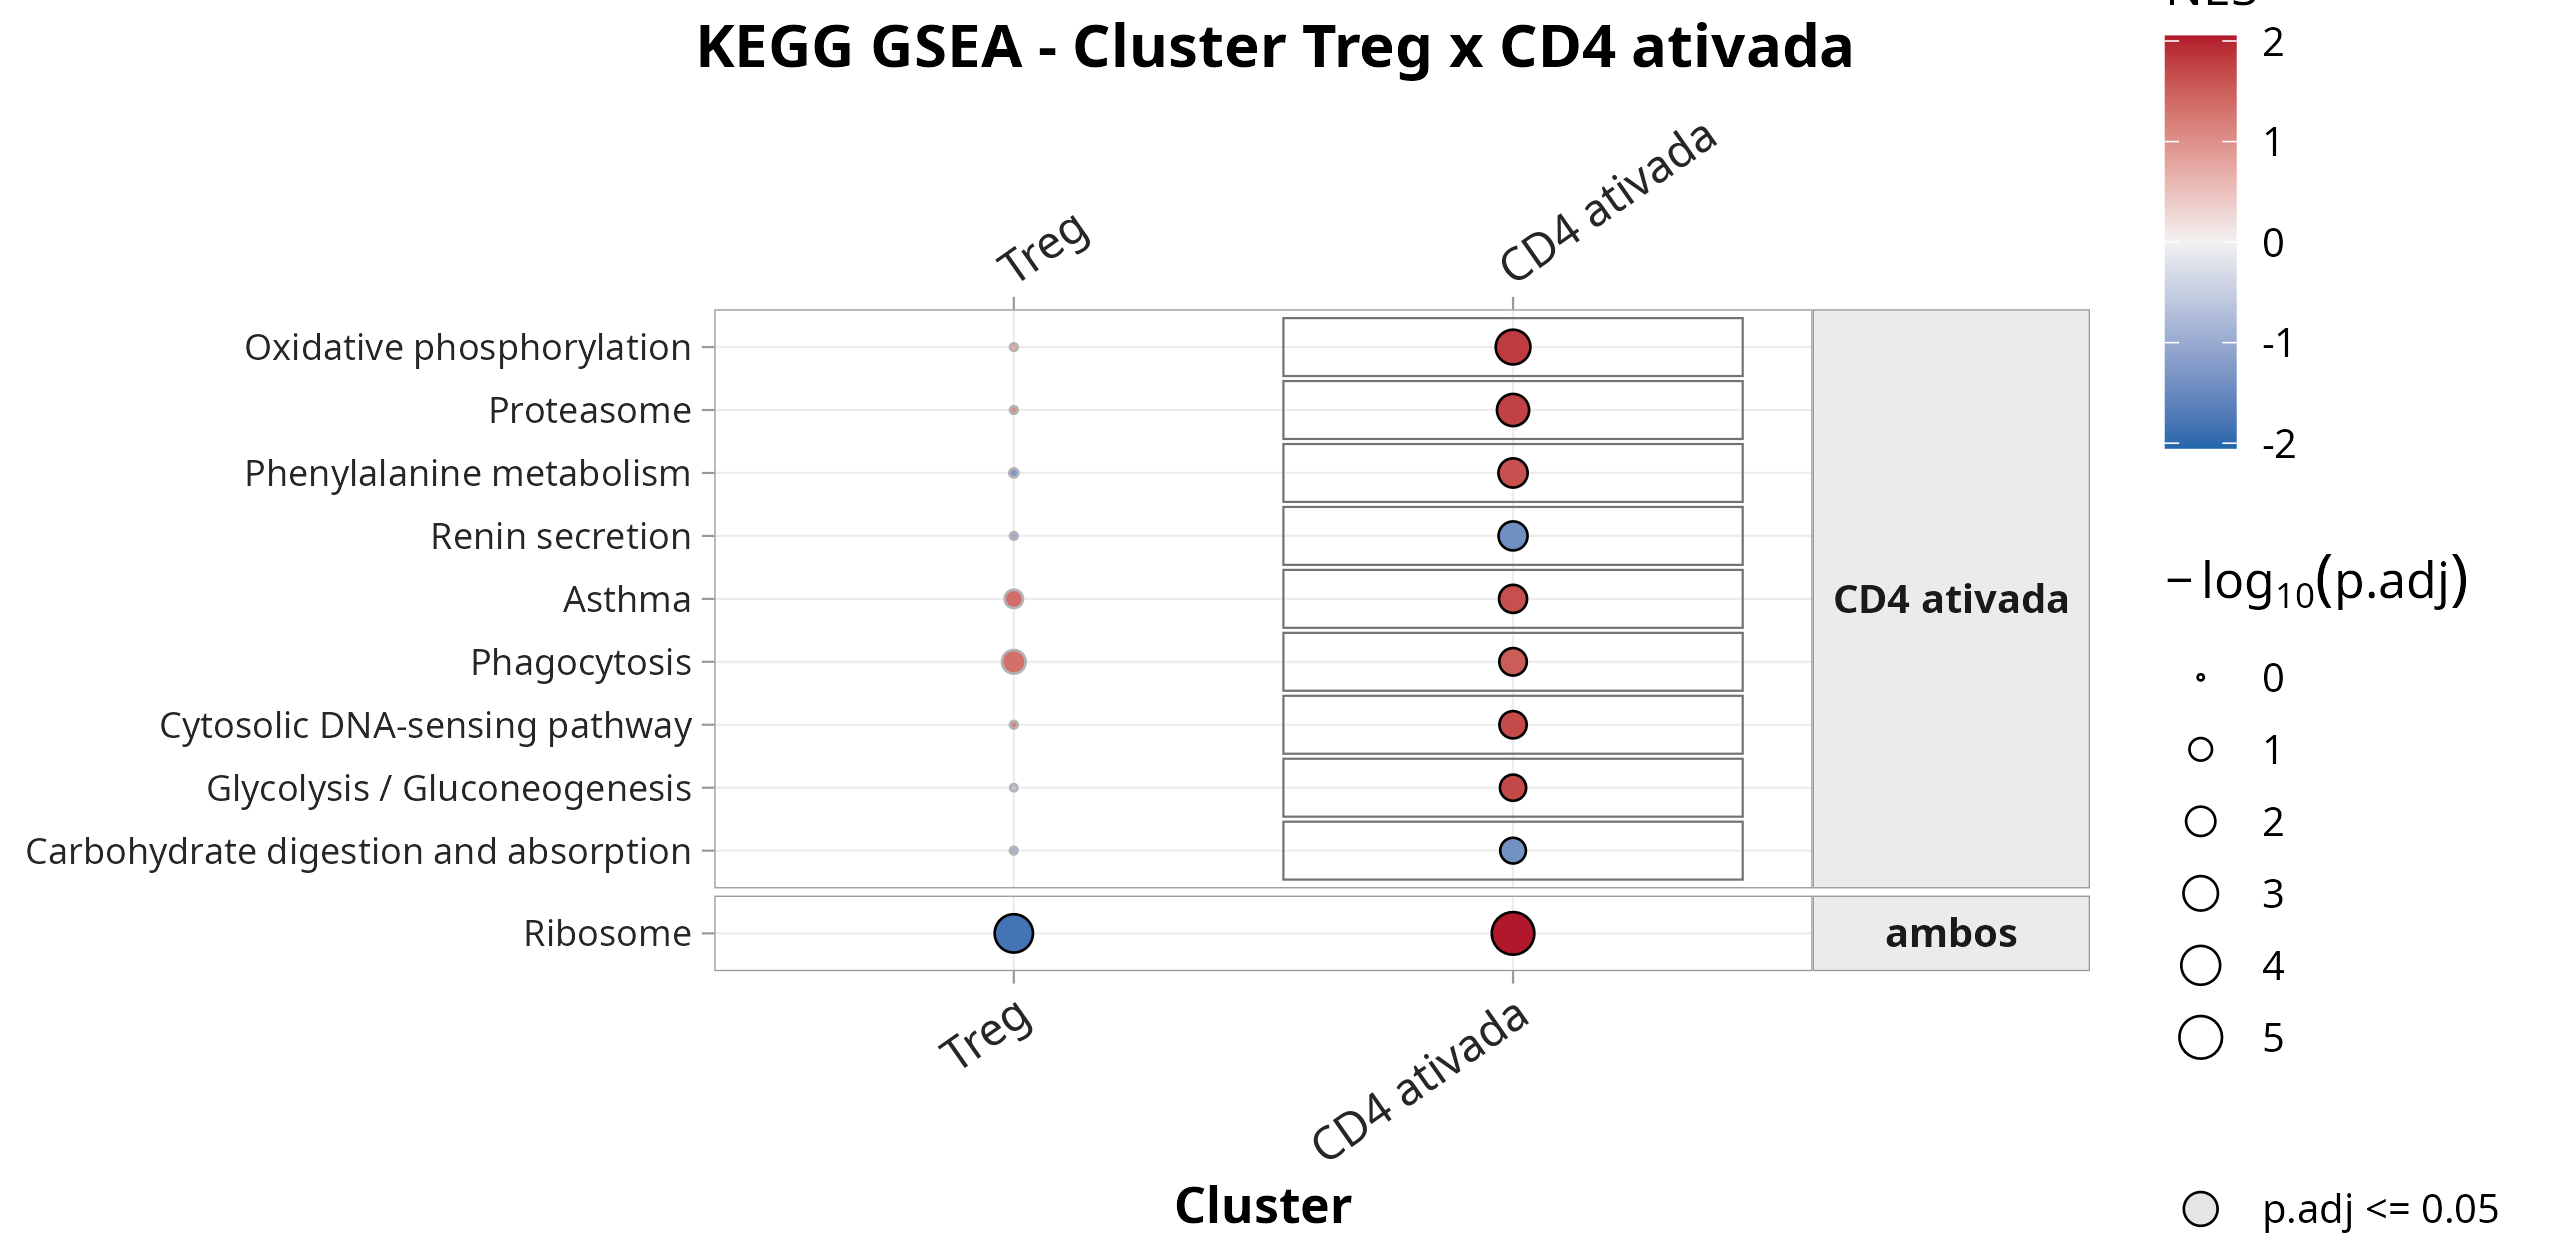

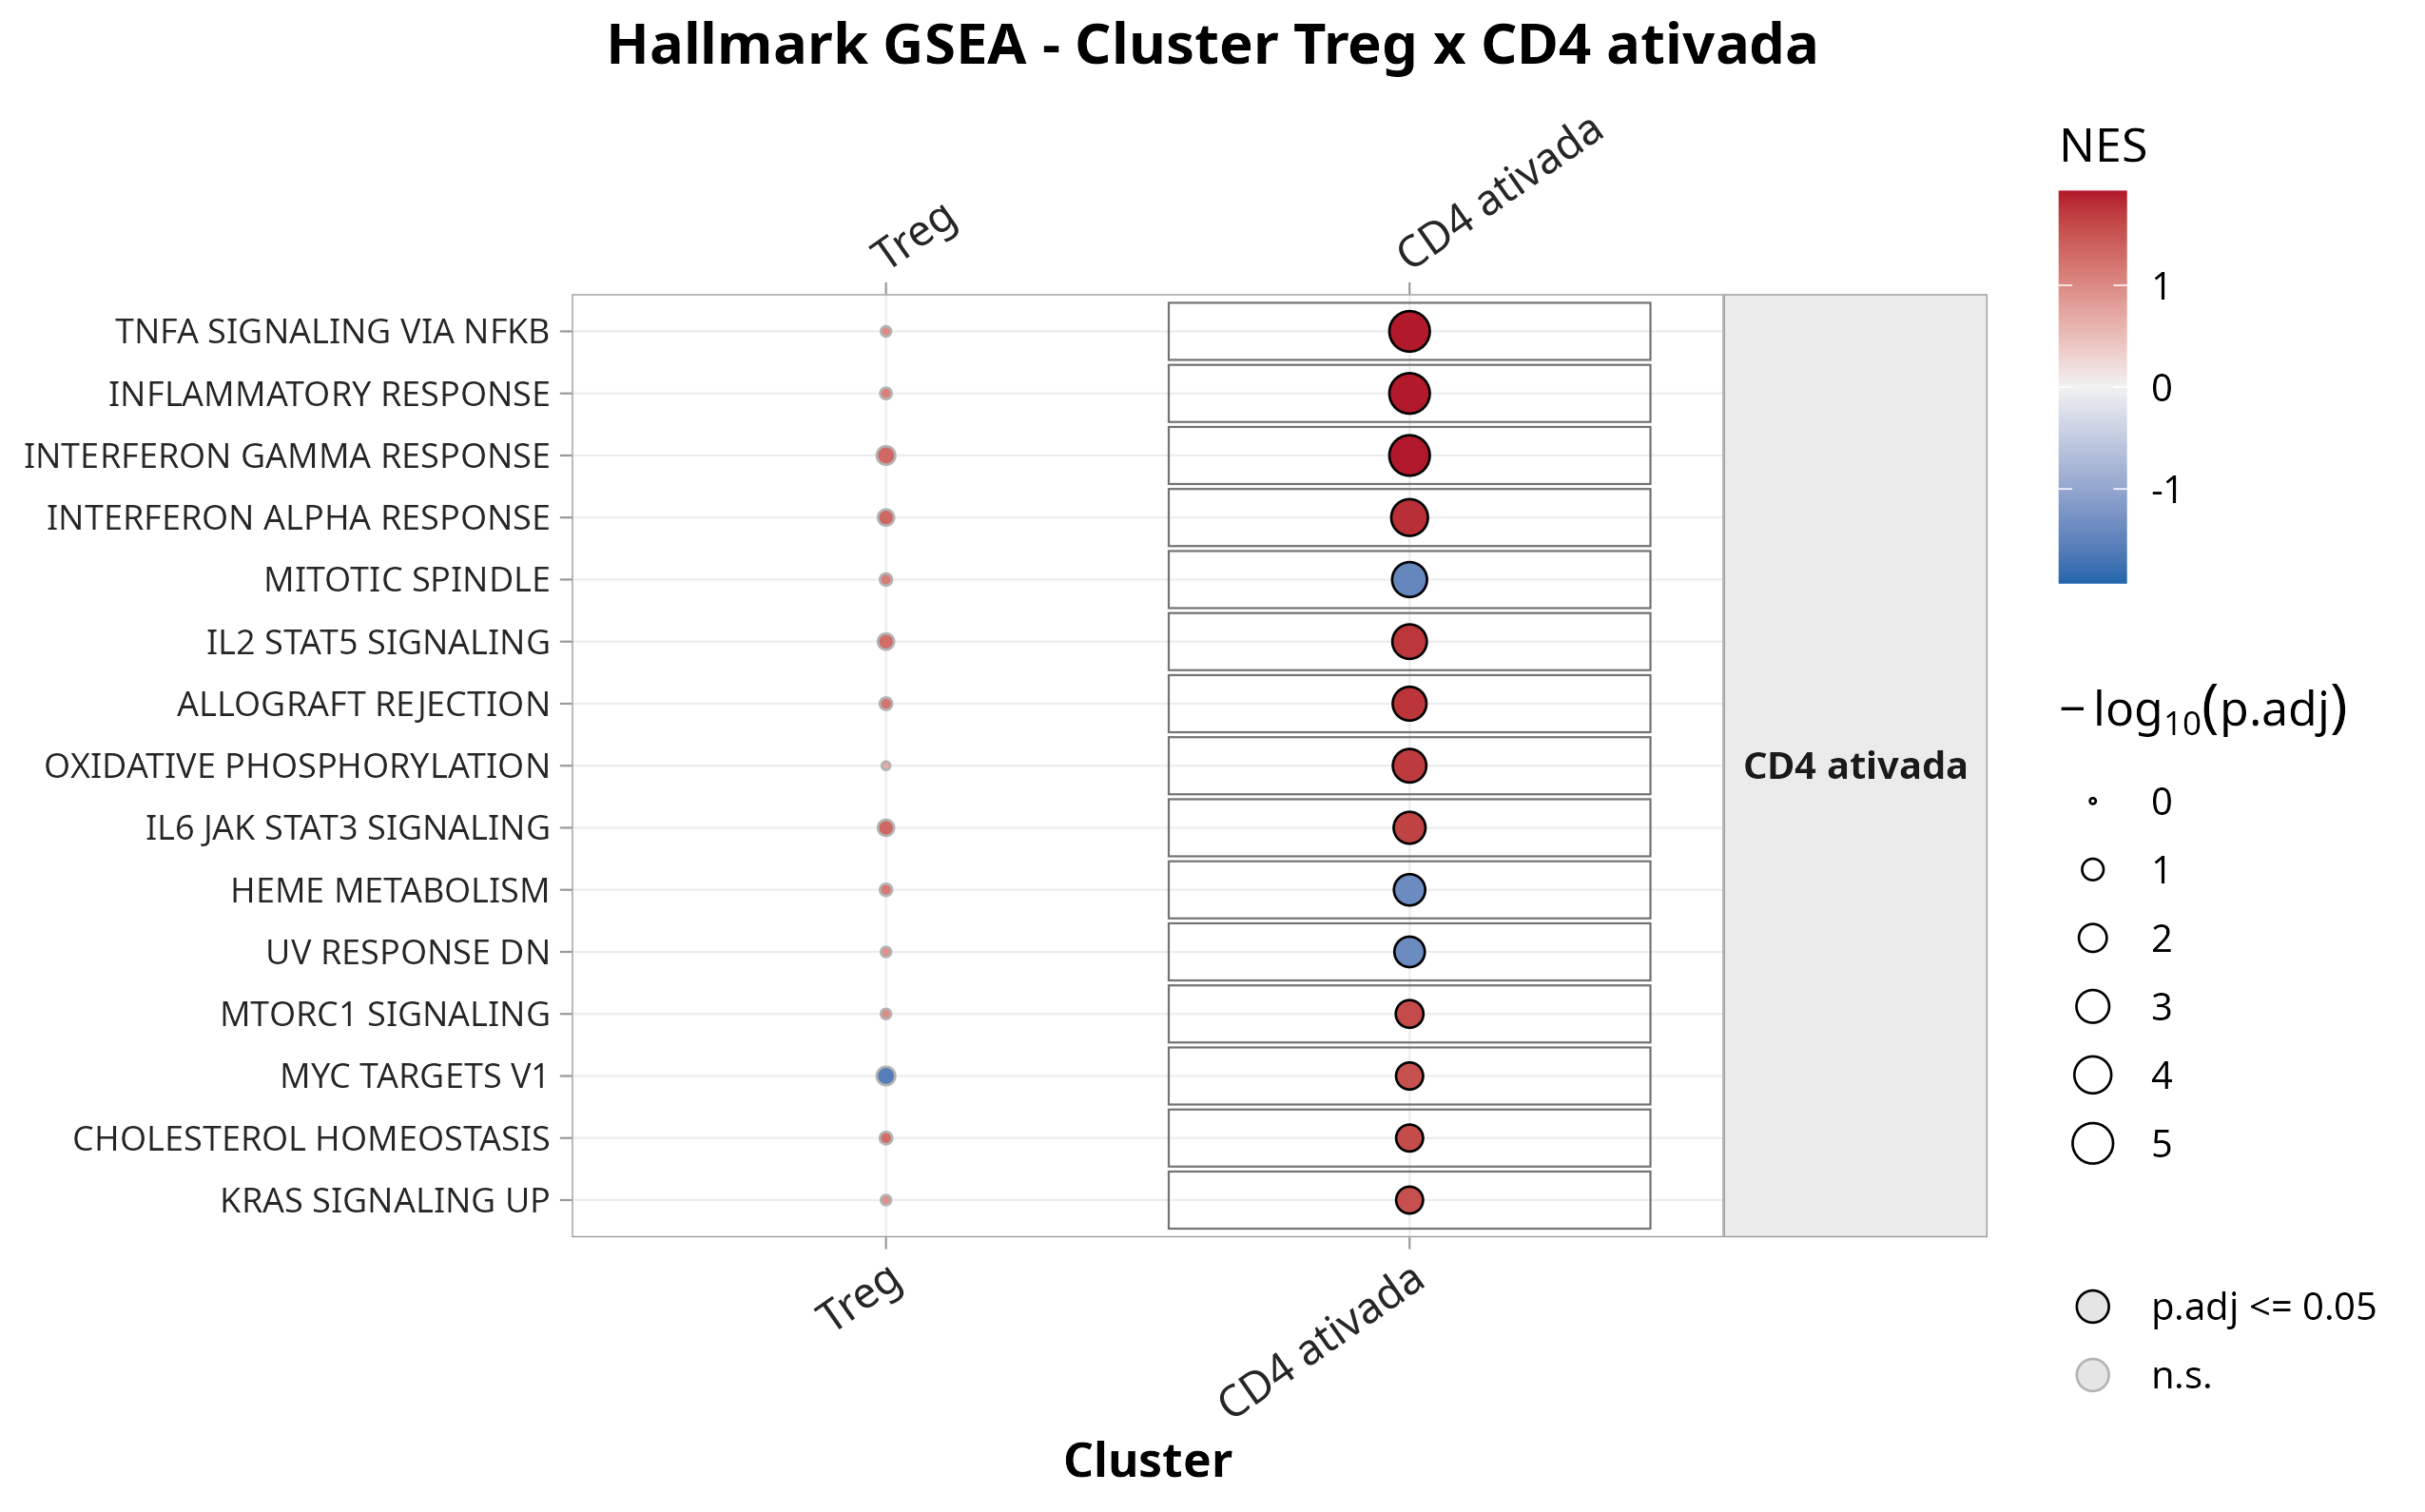

In [8]:
for b in ["reactome", "kegg", "hallmark"]:
    p = FIG / "grupo" / f"gsea_{b}_comparacao_Treg_vs_CD4 ativada.png"
    if p.exists():
        display(Image(filename=str(p), width=850))

## 6. Interpretação

**As 5 categorias do `grupo`.** Os marcadores batem com os nomes:

* CD4 ativada: TNFRSF4 (OX40), TNFRSF18 (GITR), IL2RA, MIR155HG, LTA;
* Treg: FOXP3, IKZF2, TIGIT, RTKN2, CTLA4;
* CD4 citotóxica: CCL5, NKG7, GNLY, PRF1, GZMB.

* **CD4 ativada** concentra as vias (70 Reactome, 52 KEGG, 17 Hallmark), quase todas mais altas
  nela: TNF-α/NF-κB, resposta inflamatória, interferon γ e α, IL2–STAT5, IL6–JAK–STAT3, mTORC1,
  fosforilação oxidativa, tradução e ribossomo, apresentação de antígeno. É o programa de
  ativação e de crescimento celular, coerente com a expansão dessa categoria no estímulo (P15).
* **CD4 citotóxica**: MYC targets, ribossomo e rRNA mais baixos (39 Reactome, todas NES < 0) —
  célula diferenciada e quiescente em biossíntese.
* **Treg**: MHC classe II e interferon mais altos; tradução e rRNA mais baixos (32 Reactome).
* **CD4 naive**: MYC targets e rRNA mais altos, TNF-α e MHC II mais baixos. **CD4 memória**:
  quase nada próprio (é o "meio" das outras categorias).

**Treg × T efetora (contraste principal, Teff ampla).** Com o score do espacial já passam 22 vias
Reactome e 1 KEGG (no atlas L2, nenhuma). Com os scores alternativos, mais; o sinal do NES
concorda nos quatro rankings em 115 de 138 vias Reactome.

* **Mais alto na Treg:** sinalização por **interferon** (Reactome p.adj 0,012 no score do
  espacial; Hallmark IFN-α e IFN-γ p.adj < 0,001 com sinal × −log10 p), **MHC classe II**
  (p.adj 0,052; 0,008), **TCR**, **CD28 e coinibição por PD-1**, ciclo celular (G2M, E2F) e, com
  sinal × −log10 p, **IL2–STAT5** (p.adj 0,022) — o eixo IL-2 é o clássico da Treg. Com só o
  log2FC o IL2–STAT5 inverte o sinal (n.s.), então ele depende do score.
* **Mais alto na Teff:** **ribossomo, tradução e processamento de rRNA** em todos os rankings
  (KEGG Ribosome p.adj 0,008 no score do espacial); com o log2FC, também TNF-α/NF-κB, inflamação,
  IL-17, quimiocinas, citocinas e citotoxicidade NK — o programa efetor.
* **Teff estrita** (só ativada, citotóxica e Tem GZMK⁺) dá o mesmo padrão de ribossomo/tradução
  (30 Reactome), e o interferon deixa de passar: a ativada também tem interferon alto.

**Comparação com o atlas (`P16_gsea_vias_atlasL2`).** As vias da Treg são as mesmas (interferon,
TCR, MHC II, PD-1, ciclo celular), e as da Teff também (inflamação, IL-17, citotoxicidade). Com a
anotação aparece, além disso, a diferença de biossíntese (ribossomo/tradução), que no atlas não
passava.

**Limites.** É um GSEA de marcadores no nível da célula, com NS e ML juntos: descreve o que
distingue as categorias, não o efeito do estímulo nem dos grupos clínicos. O score do espacial
(log2FC × −log10 p) dá pouco poder com o ranking completo, porque o −log10 p vai a ~300 nos
genes mais fortes; as variantes estão lado a lado na tabela `treg_vs_teff_sensibilidade`.

## Problemas encontrados

In [9]:
pequenos = tam["grupo"][tam["grupo"] < 50]
log.add("MINOR", "seção 1", "categorias com poucas células no GSEA",
        evidence="; ".join(f"{k}: {v} células" for k, v in pequenos.items()) or "nenhum",
        impact="ranking ruidoso; as vias desses clusters são frágeis",
        recommendation="não interpretar vias de clusters com < 50 células sem confirmação")
log.add("INFO", "seção 2", "parâmetros do FindAllMarkers do espacial desconhecidos",
        evidence="usado o ranking completo, sem cortes (logfc.threshold = 0, min.pct = 0, return.thresh = Inf)",
        impact="NES e vias podem diferir do que o espacial teria dado com os parâmetros dele",
        recommendation="se os parâmetros do espacial aparecerem, rodar de novo com eles para comparar")
df_issues = log.save()
issues.show(df_issues)

severity,location,problem,evidence,impact,recommendation
MINOR,seção 1,categorias com poucas células no GSEA,nenhum,ranking ruidoso; as vias desses clusters são frágeis,não interpretar vias de clusters com < 50 células sem confirmação
INFO,seção 2,parâmetros do FindAllMarkers do espacial desconhecidos,"usado o ranking completo, sem cortes (logfc.threshold = 0, min.pct = 0, return.thresh = Inf)",NES e vias podem diferir do que o espacial teria dado com os parâmetros dele,"se os parâmetros do espacial aparecerem, rodar de novo com eles para comparar"
